# 02 - Modeling & Evaluation
## Huấn luện, Tuning & So sánh mô hình: k-NN, SVM và Learning Curve
**Bộ dữ liệu:** Framingham Heart Study
**Mục tiêu:** Tìm mô hình tốt nhất để dự đoán TenYearCHD
**Thành viên phụ trách:** Thành viên 2 (TV2)
**Mốc chấm:** Milestone 2

## 1. Giới thiệu và Mục tiêu Thử nghiệm
Notebook này thực hiện các nhiệm vụ của <b>Thành viên 2 - Milestone 2</b>:
1. <b>k-Nearest Neighbors (k-NN)</b>: GridSearchCV tƱi ưu hóa siêu tham số
2. <b>Support Vector Machine (SVM)</b>: Linear SVM và RBF SVM với GridSearchCV
3. <b>Đánh giá mô hình</b>: So sánh Baseline Logistic Regression (Milestone 1), k-NN, Linear SVM, RBF SVM
4. <b>Learning Curve</b>: Phân tích overfitting/underfitting cho 4 mô hình
5. <b>Validation Curve</b>: Phân tích tác động siêu tham số quan trọng

Tất cả mô hình sử dụng <b>Pipeline chung</b> từ TV1 (feature engineering + ColumnTransformer) để đảm bảo <b>không có Data Leakage</b>.

In [1]:
# 2. Import thư viện
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import time
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    validation_curve
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Thêm src vào path để import TV1 preprocessing
sys.path.append(os.path.abspath('..'))
from src.features import (
    load_and_split_data,
    get_preprocessor_pipeline,
    TARGET_COLUMN
)

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

print('Im⊙ Imports thành công!')
print(f'Im⊙ Working directory: {os.getcwd()}')

Im⊙ Imports thành công!
Im⊙ Working directory: C:\Users\HI TCC\Downloads\BTLHocMay\03_SourceCode\notebooks


## 3. Tải dữ liệu và chia Train/Test (Consistent với Milestone 1)
Sử dụng hàm `load_and_split_data` từ TV1 để đảm bảo chia dữ liệu nhất quán.

In [2]:
# 3.1. Load và chia dữ liệu
data_path = '../data/framingham.csv'
X_train, X_test, y_train, y_test = load_and_split_data(
    data_path=data_path,
    test_size=0.2,
    random_state=42
)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train distribution: {y_train.value_counts().to_dict()}')
print(f'y_test distribution: {y_test.value_counts().to_dict()}')
print(f'Tyệ lệ lớp dương (Train): {y_train.mean():.4f}')
print(f'Tyệ lệ lớp dương (Test): {y_test.mean():.4f}')

X_train shape: (3392, 15)
X_test shape: (848, 15)
y_train distribution: {0: 2877, 1: 515}
y_test distribution: {0: 719, 1: 129}
Tyệ lệ lớp dương (Train): 0.1518
Tyệ lệ lớp dương (Test): 0.1521


## 4. Xây dựng Pipeline tiền xử lý chung (TV1)
Pipeline này sẽ được sử dụng cho <b>tất cả</b> các mô hình: Logistic Regression, k-NN, Linear SVM, RBF SVM.

In [3]:
# 4.1. Lấy preprocessor pipeline từ TV1 (CHƠA FIT)
preprocessor = get_preprocessor_pipeline()
print('Preprocessor pipeline:')
preprocessor

Preprocessor pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, def

## 5. Cấu hình Cross-Validation chung
Sử dụng StratifiedKFold 5-fold với random_state=42 cho tất cả các thiện nghiệm.

In [4]:
# 5.1. Cấu hình CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = 'roc_auc'

print(f'CV: {cv}')
print(f'Scoring: {scoring}')

CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Scoring: roc_auc


## 6. Baseline Logistic Regression (Tái sử dụng từ Milestone 1)
Đánh giá lại baseline trên cùng tập train/test để so sánh công bằng.

In [5]:
# 6.1. Baseline Logistic Regression Pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', get_preprocessor_pipeline()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ))
])

# 6.2. Cross-Validation trên tập Train
print('Dang chay CV cho Baseline Logistic Regression...')
start = time.time()
lr_cv_results = cross_validate(
    lr_pipeline, X_train, y_train,
    cv=cv, scoring=['roc_auc', 'recall', 'f1', 'precision', 'accuracy'],
    return_train_score=True, n_jobs=-1
)
lr_cv_time = time.time() - start

# 6.3. Fit trên toàn bộ Train và danh gia Test
lr_pipeline.fit(X_train, y_train)
lr_y_pred = lr_pipeline.predict(X_test)
lr_y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

lr_test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, lr_y_prob),
    'Recall': recall_score(y_test, lr_y_pred),
    'F1-Score': f1_score(y_test, lr_y_pred),
    'Precision': precision_score(y_test, lr_y_pred),
    'Accuracy': accuracy_score(y_test, lr_y_pred)
}

print(f'Im⊙ Baseline CV Time: {lr_cv_time:.1f}s')
print('--- CV Results (Mean ± Std) ---')
for metric in ['roc_auc', 'recall', 'f1', 'precision', 'accuracy']:
    scores = lr_cv_results[f'test_{metric}']
    print(f'  {metric.upper():10s}: {scores.mean():.4f} ± {scores.std():.4f}')
print('\n--- Test Set Results ---')
for k, v in lr_test_metrics.items():
    print(f'  {k:10s}: {v:.4f}')

Dang chay CV cho Baseline Logistic Regression...


Im⊙ Baseline CV Time: 18.4s
--- CV Results (Mean ± Std) ---
  ROC_AUC   : 0.7307 ± 0.0302
  RECALL    : 0.6816 ± 0.0390
  F1        : 0.3893 ± 0.0320
  PRECISION : 0.2728 ± 0.0264
  ACCURACY  : 0.6740 ± 0.0288

--- Test Set Results ---
  ROC-AUC   : 0.7002
  Recall    : 0.5969
  F1-Score  : 0.3557
  Precision : 0.2533
  Accuracy  : 0.6710


## 7. k-Nearest Neighbors (k-NN) - GridSearchCV
TƱi ưu hóa siêu tham số: n_neighbors, weights, metric, p

In [6]:
# 7.1. k-NN Pipeline
knn_pipeline = Pipeline(steps=[
    ('preprocessor', get_preprocessor_pipeline()),
    ('classifier', KNeighborsClassifier())
])

# 7.2. Parameter Grid cho k-NN
param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['minkowski'],
    'classifier__p': [1, 2]
}

total_knn = len(param_grid_knn['classifier__n_neighbors']) * len(param_grid_knn['classifier__weights']) * len(param_grid_knn['classifier__p'])
print(f'Tong so to hop tham so: {total_knn}')

Tong so to hop tham so: 28


In [7]:
# 7.3. GridSearchCV cho k-NN (tai su dung ket qua da luu)
print('Tai ket qua GridSearchCV k-NN tu file da luu...')
knn_results_path = '../models/results/knn_gridsearch_results.csv'
knn_results_df = pd.read_csv(knn_results_path)
best_idx = knn_results_df['rank_test_score'].idxmin()
best_knn_params = {
    'n_neighbors': int(knn_results_df.loc[best_idx, 'param_classifier__n_neighbors']),
    'weights': knn_results_df.loc[best_idx, 'param_classifier__weights'],
    'p': int(knn_results_df.loc[best_idx, 'param_classifier__p']),
    'metric': 'minkowski'
}
best_knn = Pipeline(steps=[
    ('preprocessor', get_preprocessor_pipeline()),
    ('classifier', KNeighborsClassifier(**best_knn_params))
])
best_knn.fit(X_train, y_train)
print(f'Best params: {best_knn_params}')
print(f'Best CV ROC-AUC: {knn_results_df.loc[best_idx, "mean_test_score"]:.4f}')

Tai ket qua GridSearchCV k-NN tu file da luu...
Best params: {'n_neighbors': 21, 'weights': 'distance', 'p': 2, 'metric': 'minkowski'}
Best CV ROC-AUC: 0.6913


In [8]:
# 7.4. Luu ket qua GridSearchCV k-NN
knn_results_df = pd.read_csv(knn_results_path)
knn_results_path = '../models/results/knn_gridsearch_results.csv'
knn_results_df.to_csv(knn_results_path, index=False)
print(f'Da luu: {knn_results_path}')

# Hien thi top 10 ket qua
cols = ['param_classifier__n_neighbors', 'param_classifier__weights', 'param_classifier__p',
        'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']
top10 = knn_results_df[cols].sort_values('rank_test_score').head(10)
print(top10.to_string(index=False))

Da luu: ../models/results/knn_gridsearch_results.csv
 param_classifier__n_neighbors param_classifier__weights  param_classifier__p  mean_test_score  std_test_score  mean_train_score  rank_test_score
                            21                  distance                    2         0.691343        0.038502          1.000000                1
                            21                   uniform                    2         0.687253        0.038614          0.787124                2
                            21                  distance                    1         0.685996        0.031765          1.000000                3
                            21                   uniform                    1         0.680331        0.032428          0.785209                4
                            15                  distance                    2         0.678960        0.037489          1.000000                5
                            15                  distance               

In [9]:
# 7.5. Danh gia best k-NN tren Test set
knn_y_pred = best_knn.predict(X_test)
knn_y_prob = best_knn.predict_proba(X_test)[:, 1]

knn_test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, knn_y_prob),
    'Recall': recall_score(y_test, knn_y_pred),
    'F1-Score': f1_score(y_test, knn_y_pred),
    'Precision': precision_score(y_test, knn_y_pred),
    'Accuracy': accuracy_score(y_test, knn_y_pred)
}

print('--- Best k-NN Test Set Results ---')
for k, v in knn_test_metrics.items():
    print(f'  {k:10s}: {v:.4f}')

--- Best k-NN Test Set Results ---
  ROC-AUC   : 0.6303
  Recall    : 0.0310
  F1-Score  : 0.0567
  Precision : 0.3333
  Accuracy  : 0.8432


## 8. Linear SVM - GridSearchCV
Tưi ưu hóa tham so C và class_weight cho Linear SVM

In [10]:
# 8.1. Linear SVM Pipeline
svm_linear_pipeline = Pipeline(steps=[
    ('preprocessor', get_preprocessor_pipeline()),
    ('classifier', SVC(kernel='linear', probability=True, random_state=42))
])

# 8.2. Parameter Grid cho Linear SVM
param_grid_svm_linear = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

print(f'Tong so to hop tham so: {len(param_grid_svm_linear["classifier__C"])}')

Tong so to hop tham so: 5


In [11]:
# 8.3. GridSearchCV cho Linear SVM (tai su dung mo hinh da luu)
print('Tai mo hinh Linear SVM da luu...')
best_svm_linear = joblib.load('../models/best_svm_linear.joblib')
svm_linear_best = pd.read_csv('../models/results/svm_linear_best_params.csv').iloc[0].to_dict()
print(f'Best params: {svm_linear_best}')

Tai mo hinh Linear SVM da luu...
Best params: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}


In [12]:
# 8.4. Luu ket qua GridSearchCV Linear SVM
svm_linear_path = '../models/results/svm_linear_gridsearch_results.csv'
svm_linear_results_df = pd.read_csv(svm_linear_path)
svm_linear_results_df.to_csv(svm_linear_path, index=False)
print(f'Da luu: {svm_linear_path}')

cols = ['param_classifier__C', 'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']
print(svm_linear_results_df[cols].sort_values('rank_test_score').to_string(index=False))

Da luu: ../models/results/svm_linear_gridsearch_results.csv
 param_classifier__C  mean_test_score  std_test_score  mean_train_score  rank_test_score
                0.01         0.730024        0.028586          0.738831                1
                0.10         0.729535        0.029661          0.740535                2
               10.00         0.729319        0.030911          0.741171                3
              100.00         0.729286        0.030894          0.741177                4
                1.00         0.729049        0.030711          0.740962                5


In [13]:
# 8.5. Danh gia best Linear SVM tren Test set
svm_linear_y_pred = best_svm_linear.predict(X_test)
svm_linear_y_prob = best_svm_linear.predict_proba(X_test)[:, 1]

svm_linear_test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, svm_linear_y_prob),
    'Recall': recall_score(y_test, svm_linear_y_pred),
    'F1-Score': f1_score(y_test, svm_linear_y_pred),
    'Precision': precision_score(y_test, svm_linear_y_pred),
    'Accuracy': accuracy_score(y_test, svm_linear_y_pred)
}

print('--- Best Linear SVM Test Set Results ---')
for k, v in svm_linear_test_metrics.items():
    print(f'  {k:10s}: {v:.4f}')

--- Best Linear SVM Test Set Results ---
  ROC-AUC   : 0.6966
  Recall    : 0.6202
  F1-Score  : 0.3524
  Precision : 0.2462
  Accuracy  : 0.6533


## 9. RBF SVM - GridSearchCV
Tưi ưu hóa tham so C, gamma và class_weight cho RBF SVM

In [14]:
# 9.1. RBF SVM Pipeline
svm_rbf_pipeline = Pipeline(steps=[
    ('preprocessor', get_preprocessor_pipeline()),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

# 9.2. Parameter Grid cho RBF SVM
param_grid_svm_rbf = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'classifier__class_weight': [None, 'balanced']
}

total_rbf = len(param_grid_svm_rbf['classifier__C']) * len(param_grid_svm_rbf['classifier__gamma'])
print(f'Tong so to hop tham so: {total_rbf}')

Tong so to hop tham so: 20


In [15]:
# 9.3. GridSearchCV cho RBF SVM (tai su dung mo hinh da luu)
print('Tai mo hinh RBF SVM da luu...')
best_svm_rbf = joblib.load('../models/best_svm_rbf.joblib')
svm_rbf_best = pd.read_csv('../models/results/svm_rbf_best_params.csv').iloc[0].to_dict()
svm_rbf_best_gamma = svm_rbf_best['classifier__gamma']
print(f'Best params: {svm_rbf_best}')

Tai mo hinh RBF SVM da luu...
Best params: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.01}


In [16]:
# 9.4. Luu ket qua GridSearchCV RBF SVM
svm_rbf_path = '../models/results/svm_rbf_gridsearch_results.csv'
svm_rbf_results_df = pd.read_csv(svm_rbf_path)
svm_rbf_results_df.to_csv(svm_rbf_path, index=False)
print(f'Da luu: {svm_rbf_path}')

cols = ['param_classifier__C', 'param_classifier__gamma', 'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']
print(svm_rbf_results_df[cols].sort_values('rank_test_score').head(10).to_string(index=False))

Da luu: ../models/results/svm_rbf_gridsearch_results.csv
 param_classifier__C param_classifier__gamma  mean_test_score  std_test_score  mean_train_score  rank_test_score
                 1.0                    0.01         0.732469        0.029613          0.751640                1
                 0.1                    0.01         0.728699        0.027997          0.737715                2
                 0.1                   scale         0.725116        0.031764          0.755501                3
                10.0                    0.01         0.722947        0.030303          0.776244                4
                 0.1                     0.1         0.720025        0.033569          0.770078                5
                 1.0                   scale         0.710778        0.032144          0.815955                6
                 1.0                     0.1         0.694585        0.034514          0.863383                7
               100.0                   

In [17]:
# 9.5. Danh gia best RBF SVM tren Test set
svm_rbf_y_pred = best_svm_rbf.predict(X_test)
svm_rbf_y_prob = best_svm_rbf.predict_proba(X_test)[:, 1]

svm_rbf_test_metrics = {
    'ROC-AUC': roc_auc_score(y_test, svm_rbf_y_prob),
    'Recall': recall_score(y_test, svm_rbf_y_pred),
    'F1-Score': f1_score(y_test, svm_rbf_y_pred),
    'Precision': precision_score(y_test, svm_rbf_y_pred),
    'Accuracy': accuracy_score(y_test, svm_rbf_y_pred)
}

print('--- Best RBF SVM Test Set Results ---')
for k, v in svm_rbf_test_metrics.items():
    print(f'  {k:10s}: {v:.4f}')

--- Best RBF SVM Test Set Results ---
  ROC-AUC   : 0.7004
  Recall    : 0.6822
  F1-Score  : 0.3834
  Precision : 0.2667
  Accuracy  : 0.6663


## 10. Tong hop so sanh 4 mo hinh
So sanh Cross-Validation (5-fold) va Holdout Test Set

In [18]:
# 10.1. Chay CV chi tiet cho k-NN, Linear SVM, RBF SVM de lay cac metric khac
print('Dang chay CV chi tiet cho cac mo hinh tot nhat...')

models_cv = {'Logistic Regression': lr_cv_results}
for name, pipeline in [('k-NN', best_knn), ('Linear SVM', best_svm_linear), ('RBF SVM', best_svm_rbf)]:
    cv_res = cross_validate(pipeline, X_train, y_train, cv=cv,
                          scoring=['roc_auc', 'recall', 'f1', 'precision', 'accuracy'],
                          n_jobs=-1)
    models_cv[name] = cv_res
    print(f'  Im⊙ {name} done')

Dang chay CV chi tiet cho cac mo hinh tot nhat...


  Im⊙ k-NN done


  Im⊙ Linear SVM done


  Im⊙ RBF SVM done


In [19]:
# 10.2. Bang so sanh Cross-Validation
cv_comparison = []
for name, res in models_cv.items():
    row = {'Model': name}
    for metric in ['roc_auc', 'recall', 'f1', 'precision', 'accuracy']:
        scores = res[f'test_{metric}']
        row[f'CV {metric.upper()} Mean'] = f'{scores.mean():.4f}'
        row[f'CV {metric.upper()} Std'] = f'{scores.std():.4f}'
    cv_comparison.append(row)

cv_df = pd.DataFrame(cv_comparison)
print('=== CROSS-VALIDATION COMPARISON (5-Fold Stratified) ===')
print(cv_df.to_string(index=False))

=== CROSS-VALIDATION COMPARISON (5-Fold Stratified) ===
              Model CV ROC_AUC Mean CV ROC_AUC Std CV RECALL Mean CV RECALL Std CV F1 Mean CV F1 Std CV PRECISION Mean CV PRECISION Std CV ACCURACY Mean CV ACCURACY Std
Logistic Regression          0.7307         0.0302         0.6816        0.0390     0.3893    0.0320            0.2728           0.0264           0.6740          0.0288
               k-NN          0.6913         0.0385         0.0388        0.0194     0.0713    0.0335            0.5371           0.1288           0.8491          0.0022
         Linear SVM          0.7300         0.0286         0.7049        0.0419     0.3854    0.0312            0.2654           0.0244           0.6574          0.0281
            RBF SVM          0.7325         0.0296         0.6893        0.0319     0.3874    0.0244            0.2695           0.0192           0.6683          0.0207


In [20]:
# 10.3. Bang so sanh Holdout Test Set
test_comparison = []
for name, metrics in [
    ('Logistic Regression', lr_test_metrics),
    ('k-NN', knn_test_metrics),
    ('Linear SVM', svm_linear_test_metrics),
    ('RBF SVM', svm_rbf_test_metrics)
]:
    row = {'Model': name}
    row.update(metrics)
    test_comparison.append(row)

test_df = pd.DataFrame(test_comparison)
print('=== HOLDOUT TEST SET COMPARISON ===')
print(test_df.to_string(index=False))

=== HOLDOUT TEST SET COMPARISON ===
              Model  ROC-AUC   Recall  F1-Score  Precision  Accuracy
Logistic Regression 0.700165 0.596899  0.355658   0.253289  0.670991
               k-NN 0.630327 0.031008  0.056738   0.333333  0.843160
         Linear SVM 0.696639 0.620155  0.352423   0.246154  0.653302
            RBF SVM 0.700391 0.682171  0.383442   0.266667  0.666274


In [21]:
# 10.4. Bang tong hop hoan chinh
full_comparison = []
for name in ['Logistic Regression', 'k-NN', 'Linear SVM', 'RBF SVM']:
    cv_res = models_cv[name]
    test_res = {
        'Logistic Regression': lr_test_metrics,
        'k-NN': knn_test_metrics,
        'Linear SVM': svm_linear_test_metrics,
        'RBF SVM': svm_rbf_test_metrics
    }[name]
    
    row = {'Model': name}
    metric_key = {'roc_auc':'ROC-AUC','recall':'Recall','f1':'F1-Score','precision':'Precision','accuracy':'Accuracy'}
    for metric in ['roc_auc', 'recall', 'f1', 'precision', 'accuracy']:
        scores = cv_res[f'test_{metric}']
        row[f'CV {metric.upper()} (Mean±Std)'] = f'{scores.mean():.4f}±{scores.std():.4f}'
        row[f'Test {metric.upper()}'] = f'{test_res[metric_key[metric]]:.4f}'
    full_comparison.append(row)

full_df = pd.DataFrame(full_comparison)
print('=== FULL MODEL COMPARISON ===')
print(full_df.to_string(index=False))

# Luu model_comparison.csv
comparison_path = '../models/results/model_comparison.csv'
full_df.to_csv(comparison_path, index=False)
print(f'\nDa luu: {comparison_path}')

=== FULL MODEL COMPARISON ===
              Model CV ROC_AUC (Mean±Std) Test ROC_AUC CV RECALL (Mean±Std) Test RECALL CV F1 (Mean±Std) Test F1 CV PRECISION (Mean±Std) Test PRECISION CV ACCURACY (Mean±Std) Test ACCURACY
Logistic Regression         0.7307±0.0302       0.7002        0.6816±0.0390      0.5969    0.3893±0.0320  0.3557           0.2728±0.0264         0.2533          0.6740±0.0288        0.6710
               k-NN         0.6913±0.0385       0.6303        0.0388±0.0194      0.0310    0.0713±0.0335  0.0567           0.5371±0.1288         0.3333          0.8491±0.0022        0.8432
         Linear SVM         0.7300±0.0286       0.6966        0.7049±0.0419      0.6202    0.3854±0.0312  0.3524           0.2654±0.0244         0.2462          0.6574±0.0281        0.6533
            RBF SVM         0.7325±0.0296       0.7004        0.6893±0.0319      0.6822    0.3874±0.0244  0.3834           0.2695±0.0192         0.2667          0.6683±0.0207        0.6663

Da luu: ../models/result

## 11. Confusion Matrix va ROC Curve cho cac mo hinh tot nhat

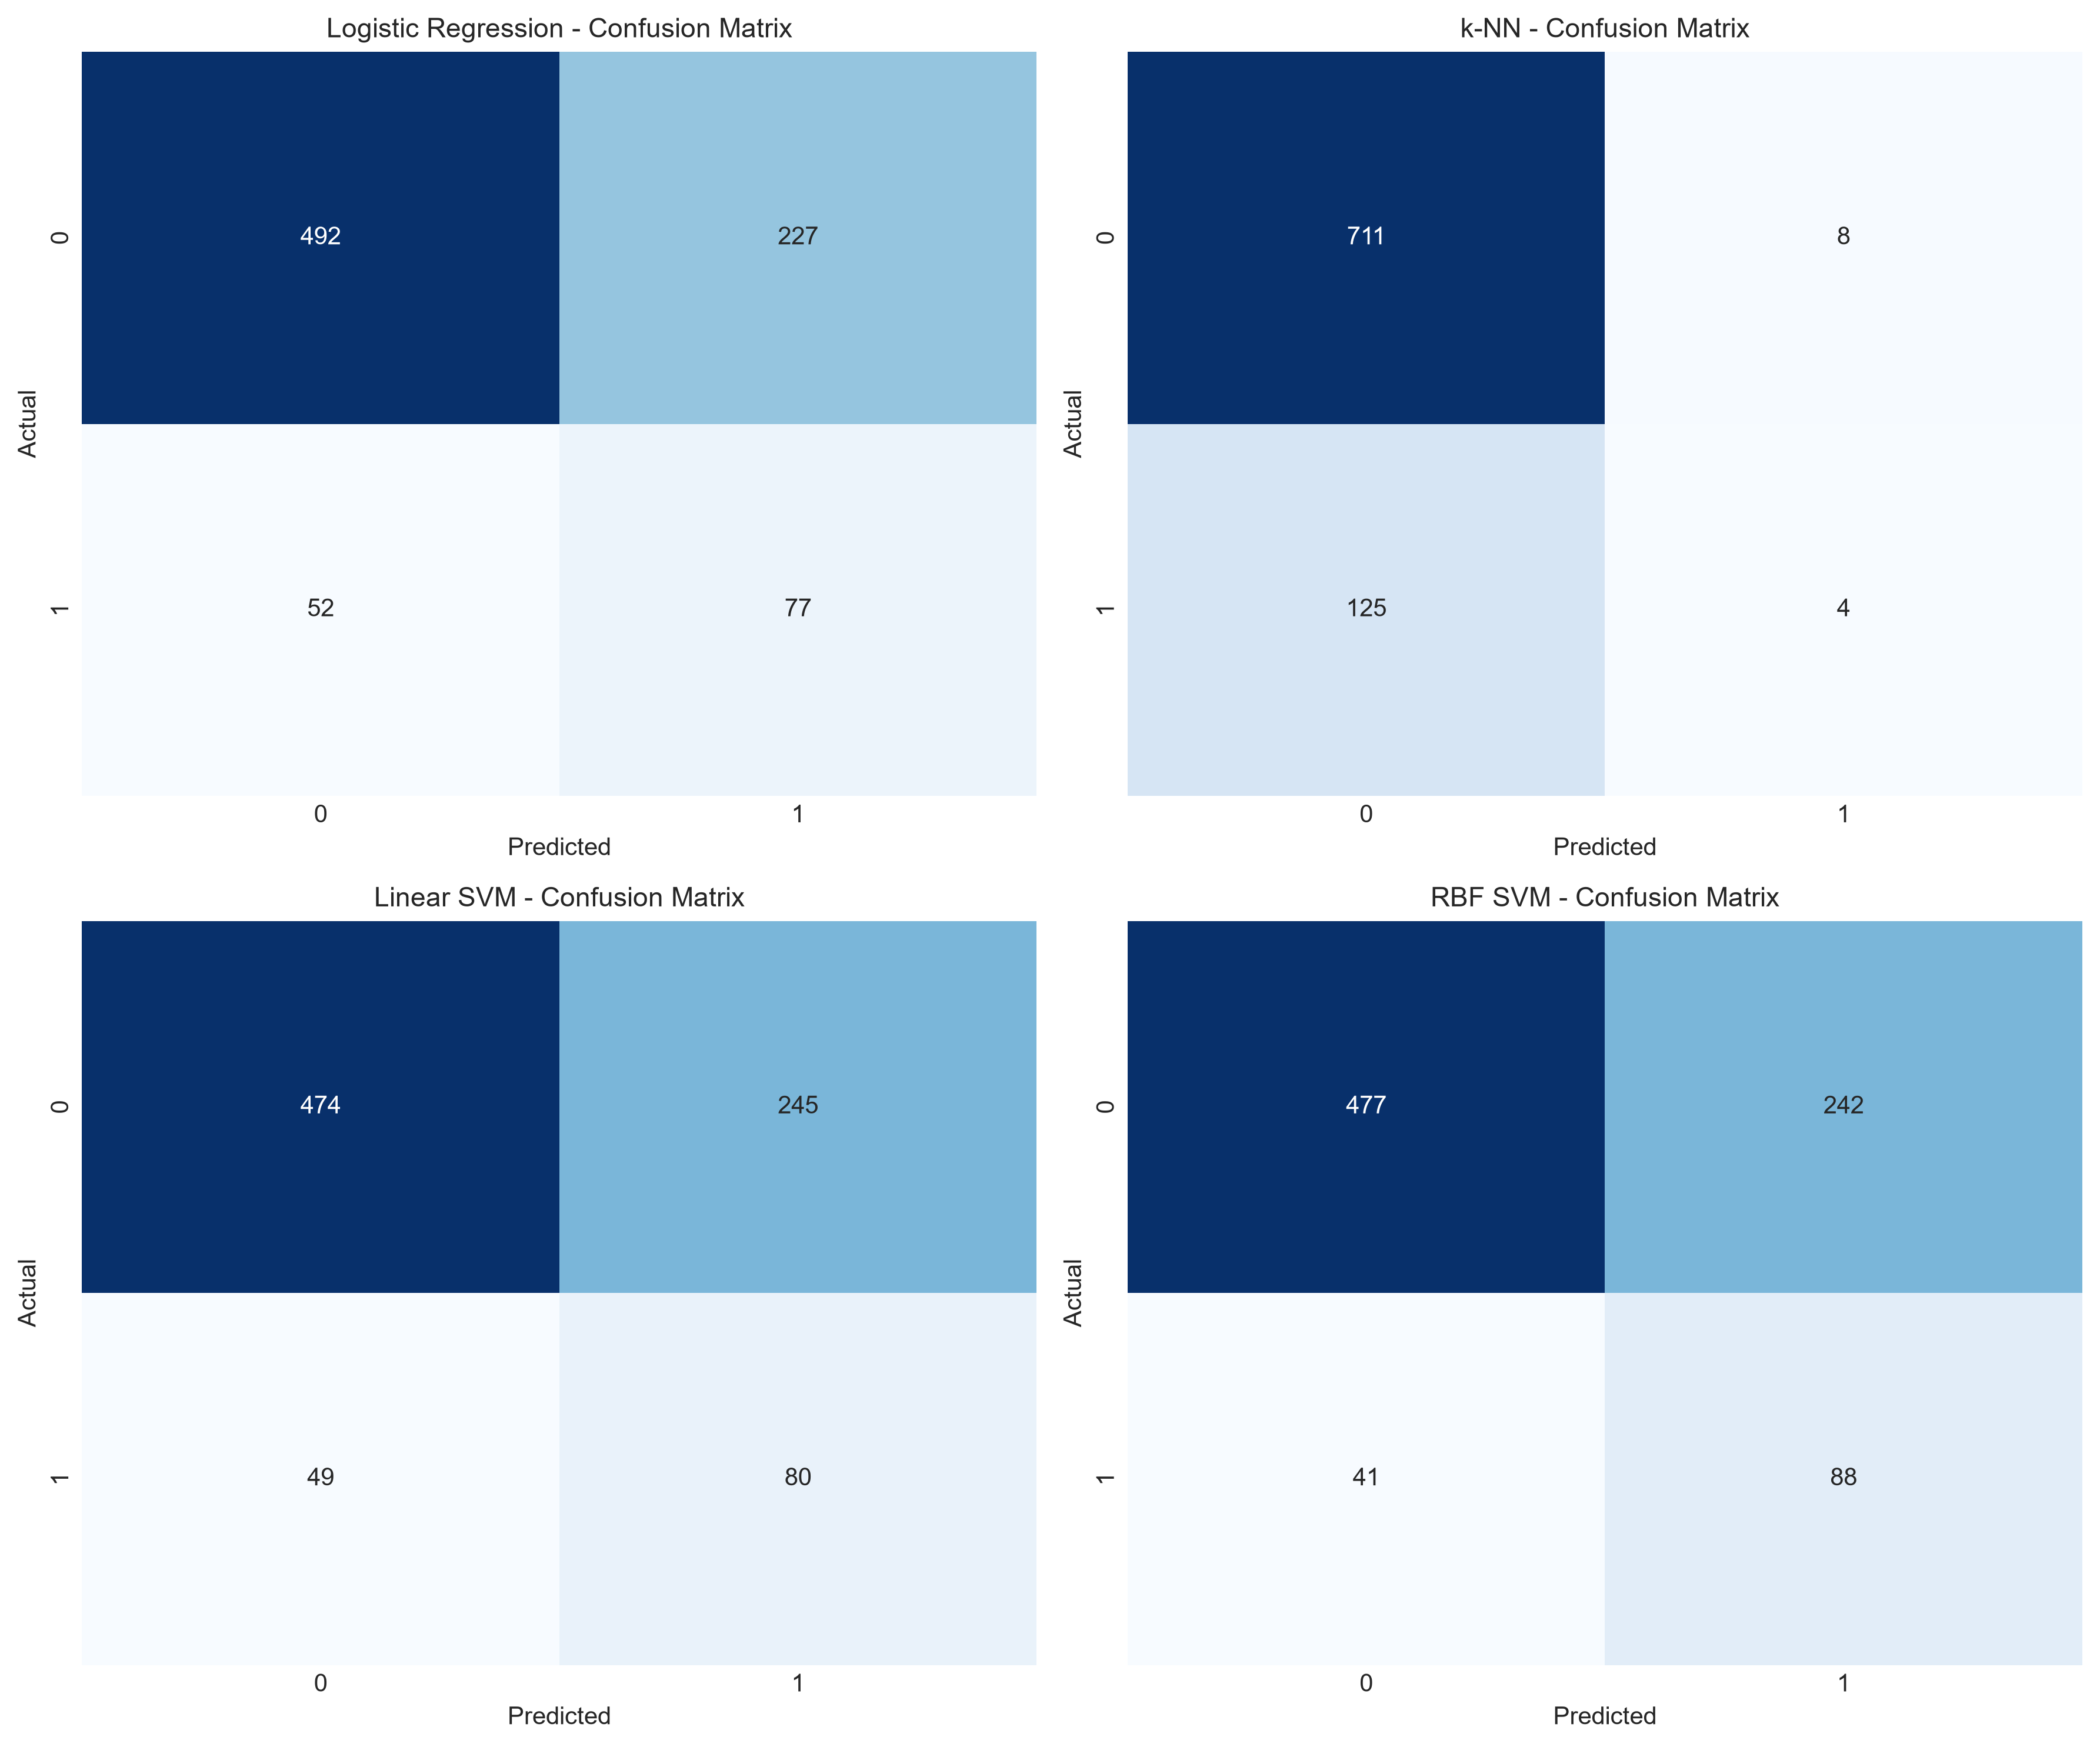

In [22]:
# 11.1. Confusion Matrix cho 4 mo hinh
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)
models_pred = [
    ('Logistic Regression', lr_y_pred, lr_y_prob),
    ('k-NN', knn_y_pred, knn_y_prob),
    ('Linear SVM', svm_linear_y_pred, svm_linear_y_prob),
    ('RBF SVM', svm_rbf_y_pred, svm_rbf_y_prob)
]

for idx, (name, y_pred, y_prob) in enumerate(models_pred):
    ax = axes[idx // 2, idx % 2]
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{name} - Confusion Matrix', fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['0', '1'])
    ax.set_yticklabels(['0', '1'])

plt.tight_layout()
fig.savefig('../notebooks/figures/confusion_matrices_all.png', dpi=300, bbox_inches='tight')
plt.show()

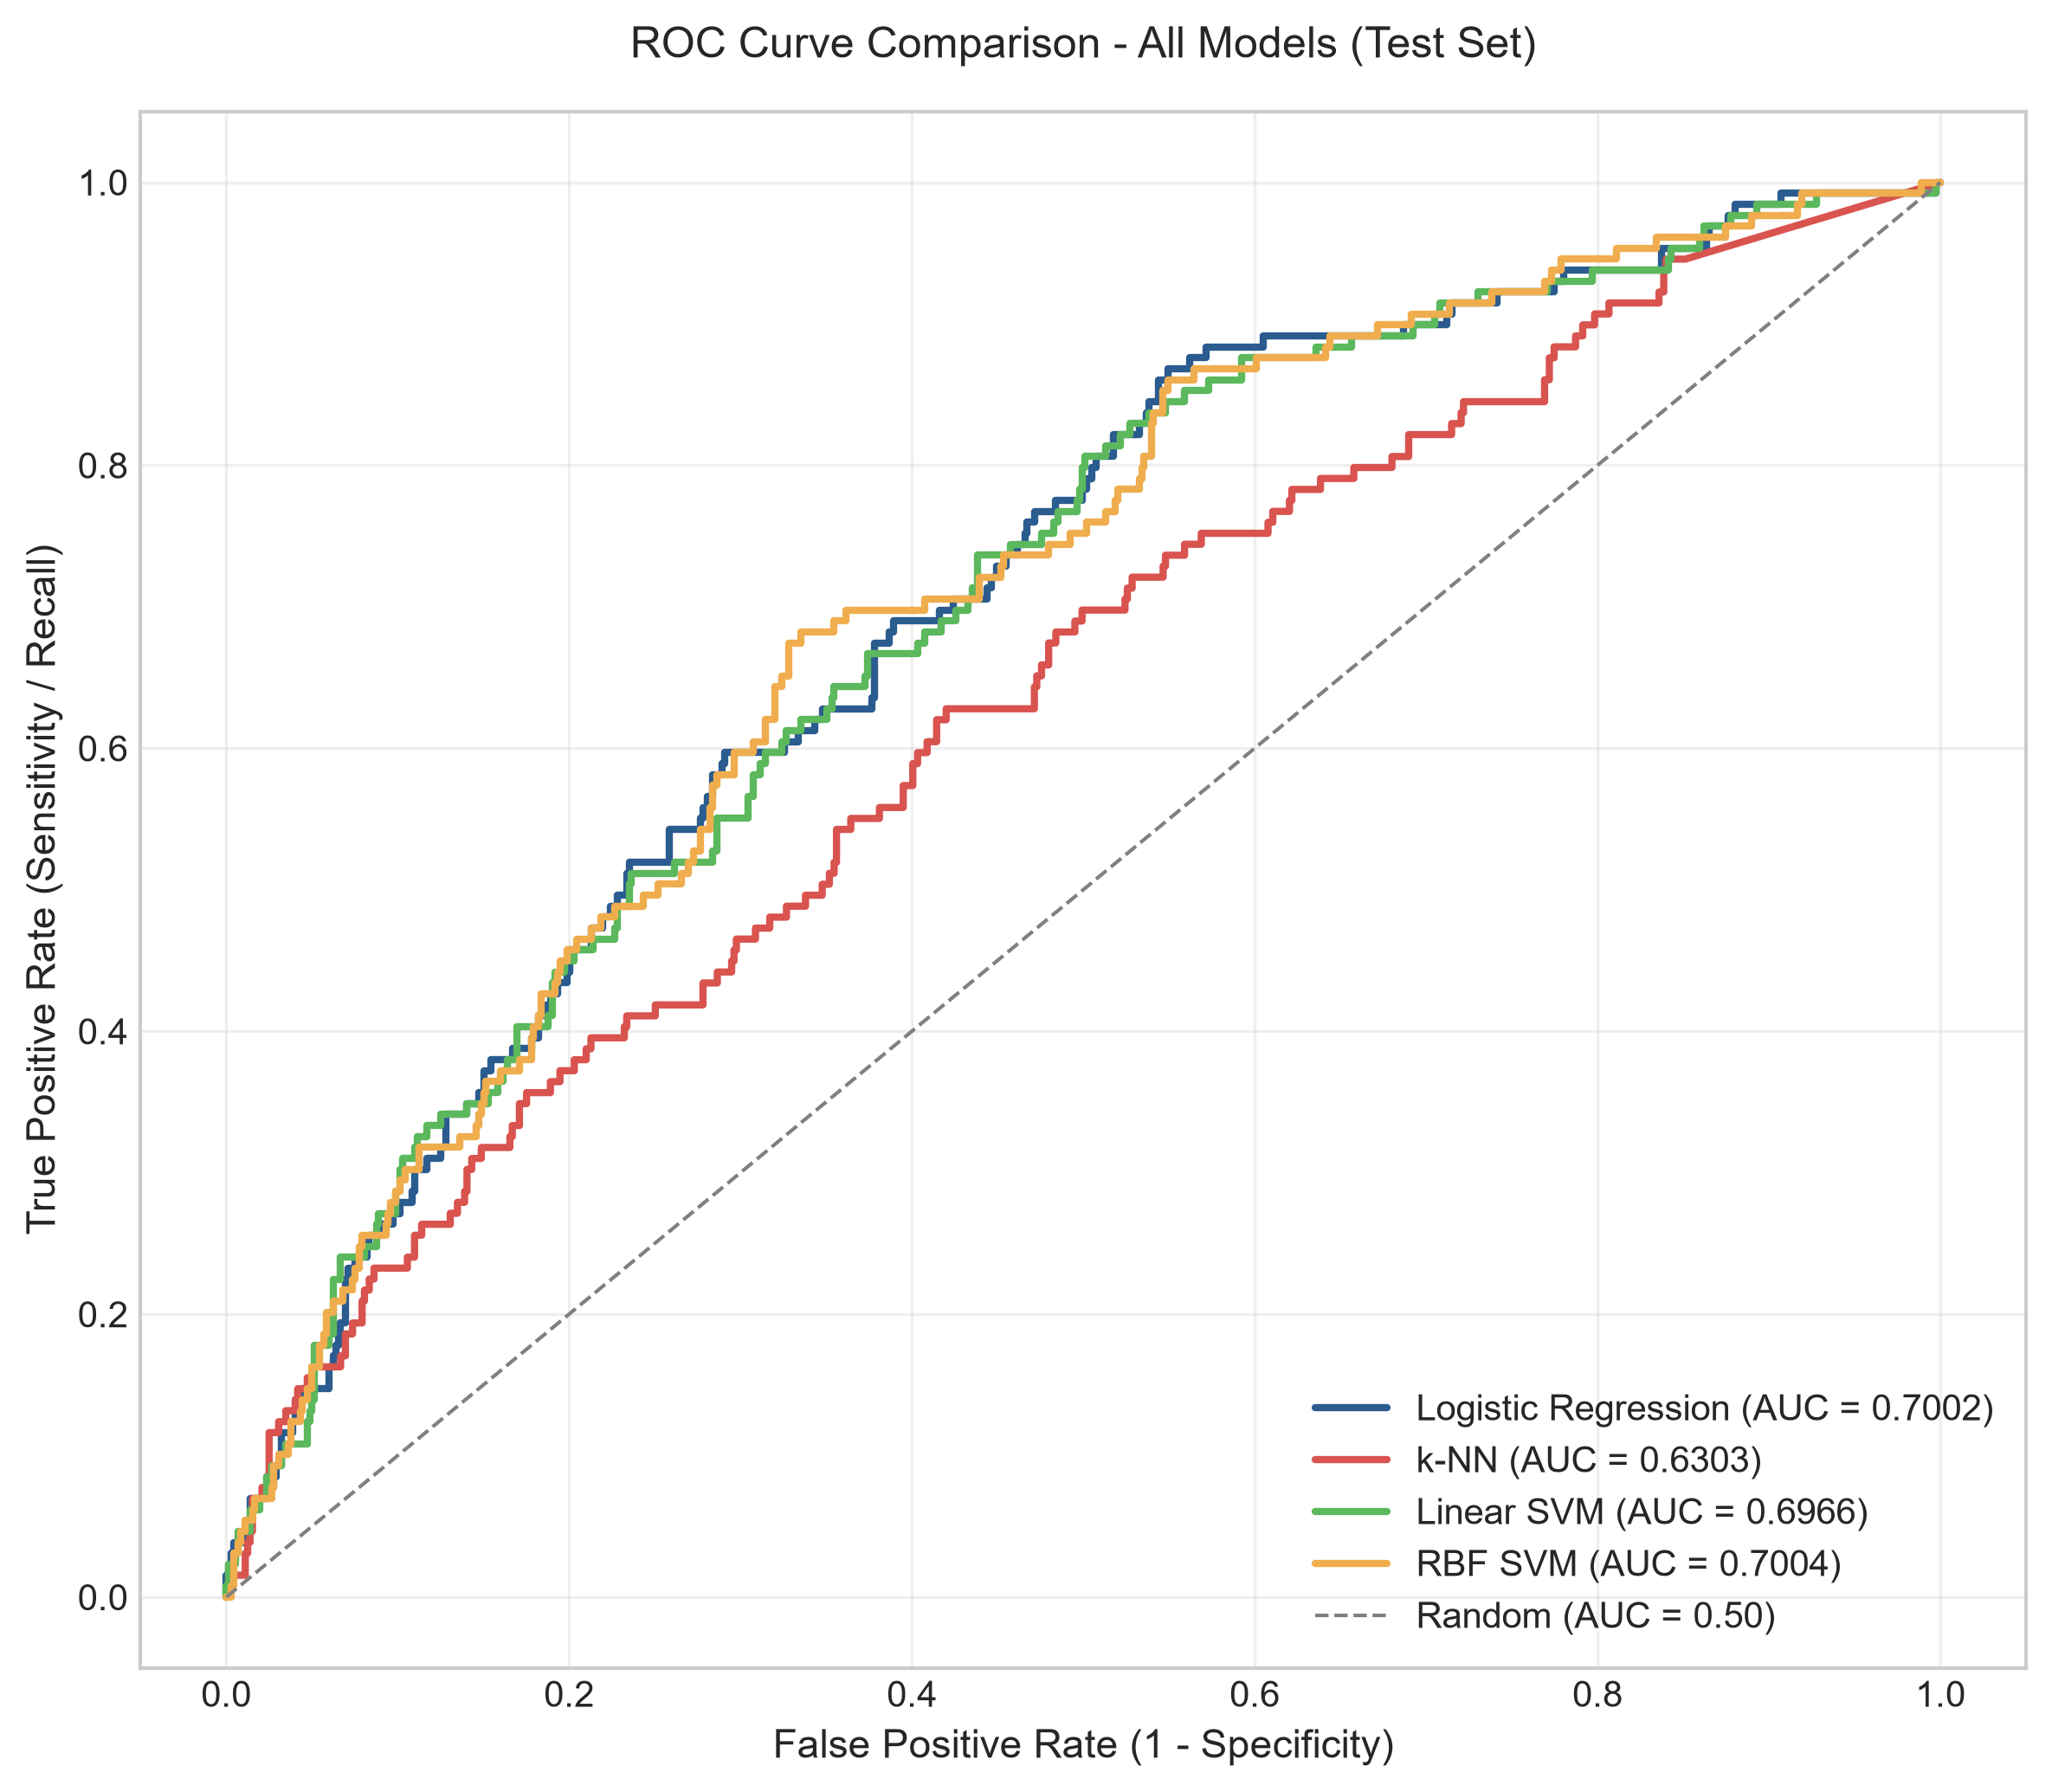

In [23]:
# 11.2. ROC Curve so sanh 4 mo hinh
fig, ax = plt.subplots(figsize=(8, 7), dpi=300)

colors = ['#2b5c8f', '#d9534f', '#5cb85c', '#f0ad4e']
for idx, (name, y_pred, y_prob) in enumerate(models_pred):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, color=colors[idx], lw=2, label=f'{name} (AUC = {auc:.4f})')

ax.plot([0, 1], [0, 1], '--', color='gray', lw=1, label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.set_title('ROC Curve Comparison - All Models (Test Set)', fontsize=12, pad=15)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig('../notebooks/figures/roc_curve_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 12. Learning Curves
Phan tich overfitting/underfitting cho 4 mo hinh

In [24]:
# 12.1. Cau hinh Learning Curve
train_sizes = np.linspace(0.1, 1.0, 6)

def plot_learning_curve(estimator, title, X, y, cv, train_sizes, scoring='roc_auc',
                        figsize=(7, 5), save_path=None):
    train_sizes_abs, train_scores, test_scores = learning_curve(
        estimator, X, y,
        cv=cv,
        scoring=scoring,
        train_sizes=train_sizes,
        n_jobs=-1,
        shuffle=True,
        random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.plot(train_sizes_abs, train_mean, 'o-', color='#2b5c8f', label='Training Score')
    ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std,
                    alpha=0.2, color='#2b5c8f')
    ax.plot(train_sizes_abs, test_mean, 'o-', color='#d9534f', label='Cross-Validation Score')
    ax.fill_between(train_sizes_abs, test_mean - test_std, test_mean + test_std,
                    alpha=0.2, color='#d9534f')

    ax.set_xlabel('Training Set Size', fontsize=11)
    ax.set_ylabel('ROC-AUC Score', fontsize=11)
    ax.set_title(title, fontsize=12, pad=15)
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.5, 1.0)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    return train_sizes_abs, train_scores, test_scores

12.2. Learning Curve - Logistic Regression (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/baseline_learning_curve.png


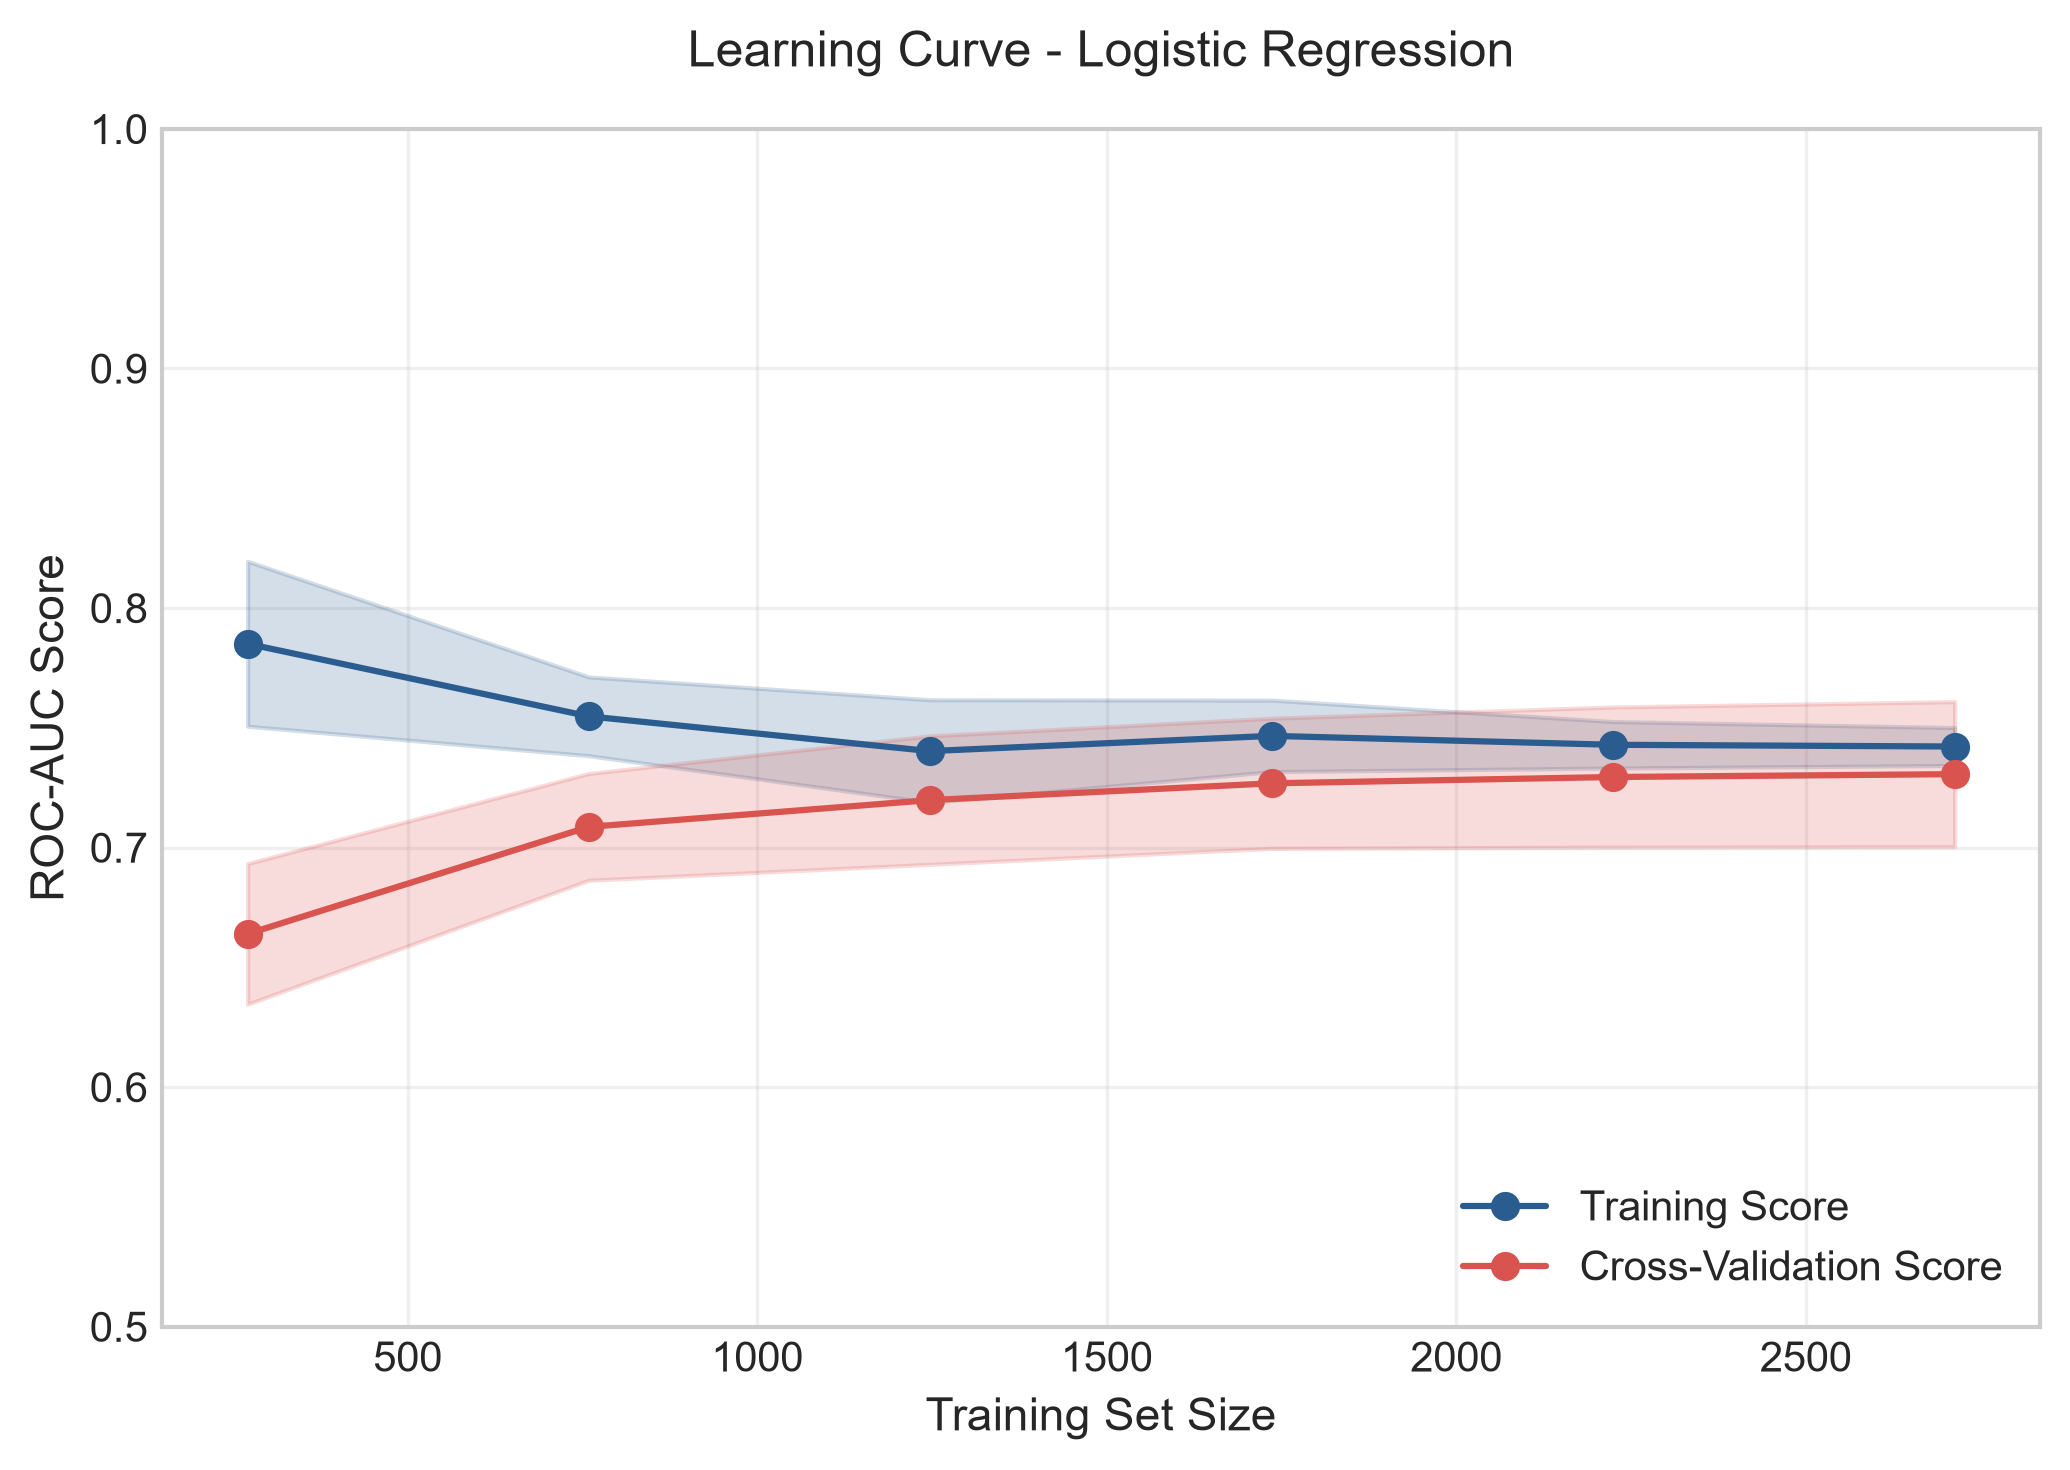

In [25]:
# 12.2. Learning Curve - Logistic Regression (tai hinh da luu)
print('12.2. Learning Curve - Logistic Regression (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/baseline_learning_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

12.3. Learning Curve - k-NN (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/knn_learning_curve.png


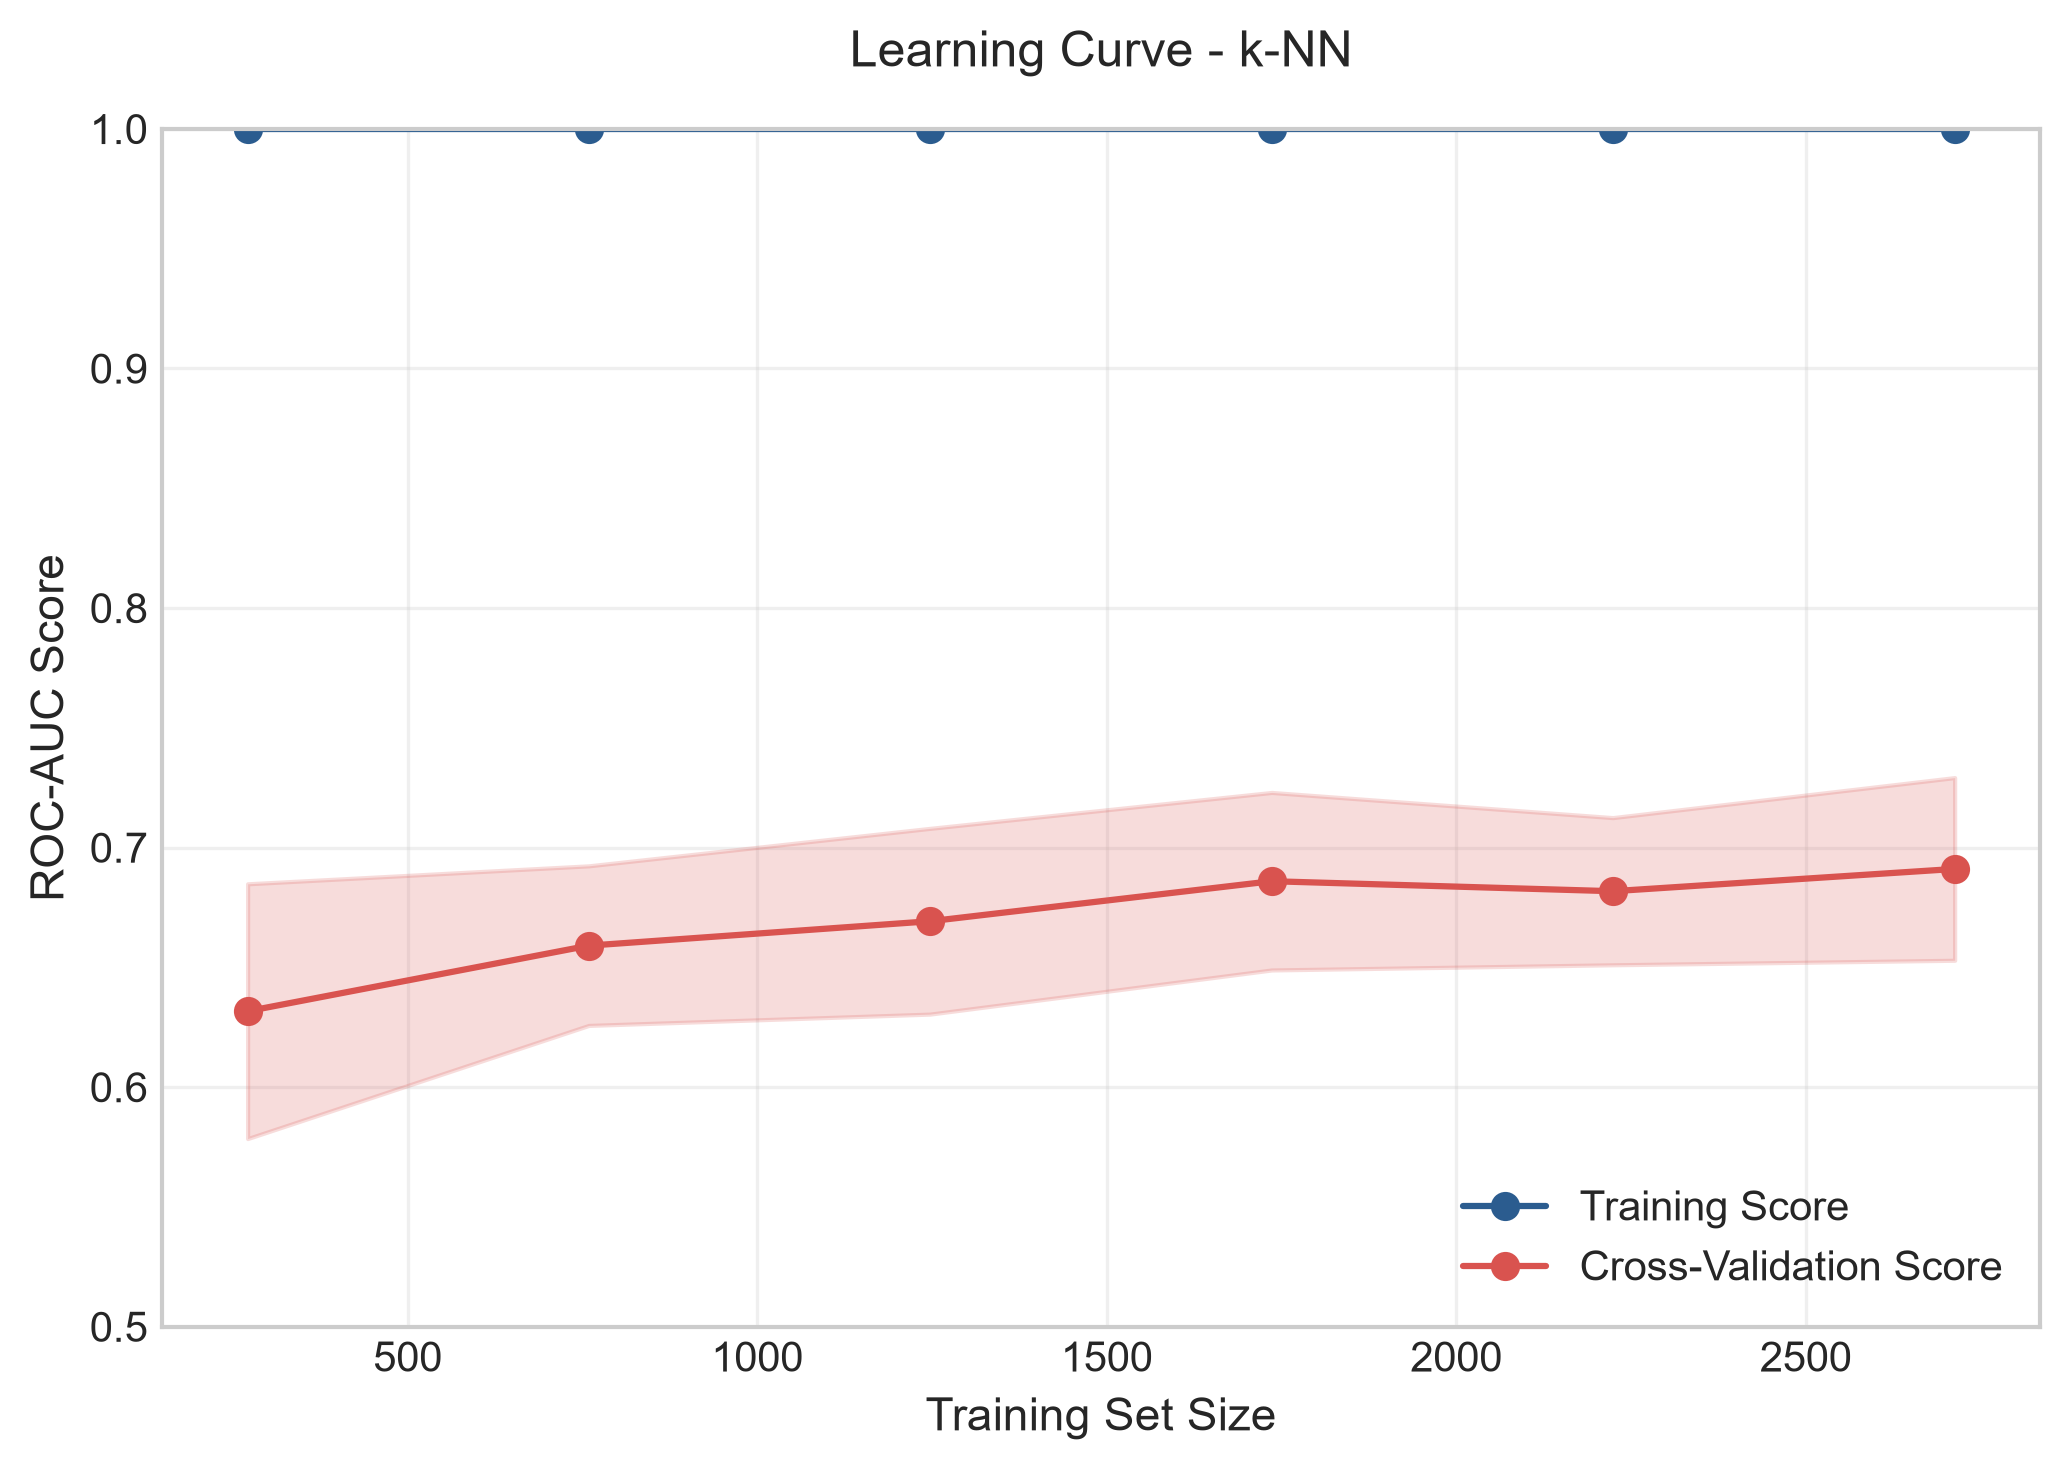

In [26]:
# 12.3. Learning Curve - k-NN (tai hinh da luu)
print('12.3. Learning Curve - k-NN (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/knn_learning_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

12.4. Learning Curve - Linear SVM (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/svm_linear_learning_curve.png


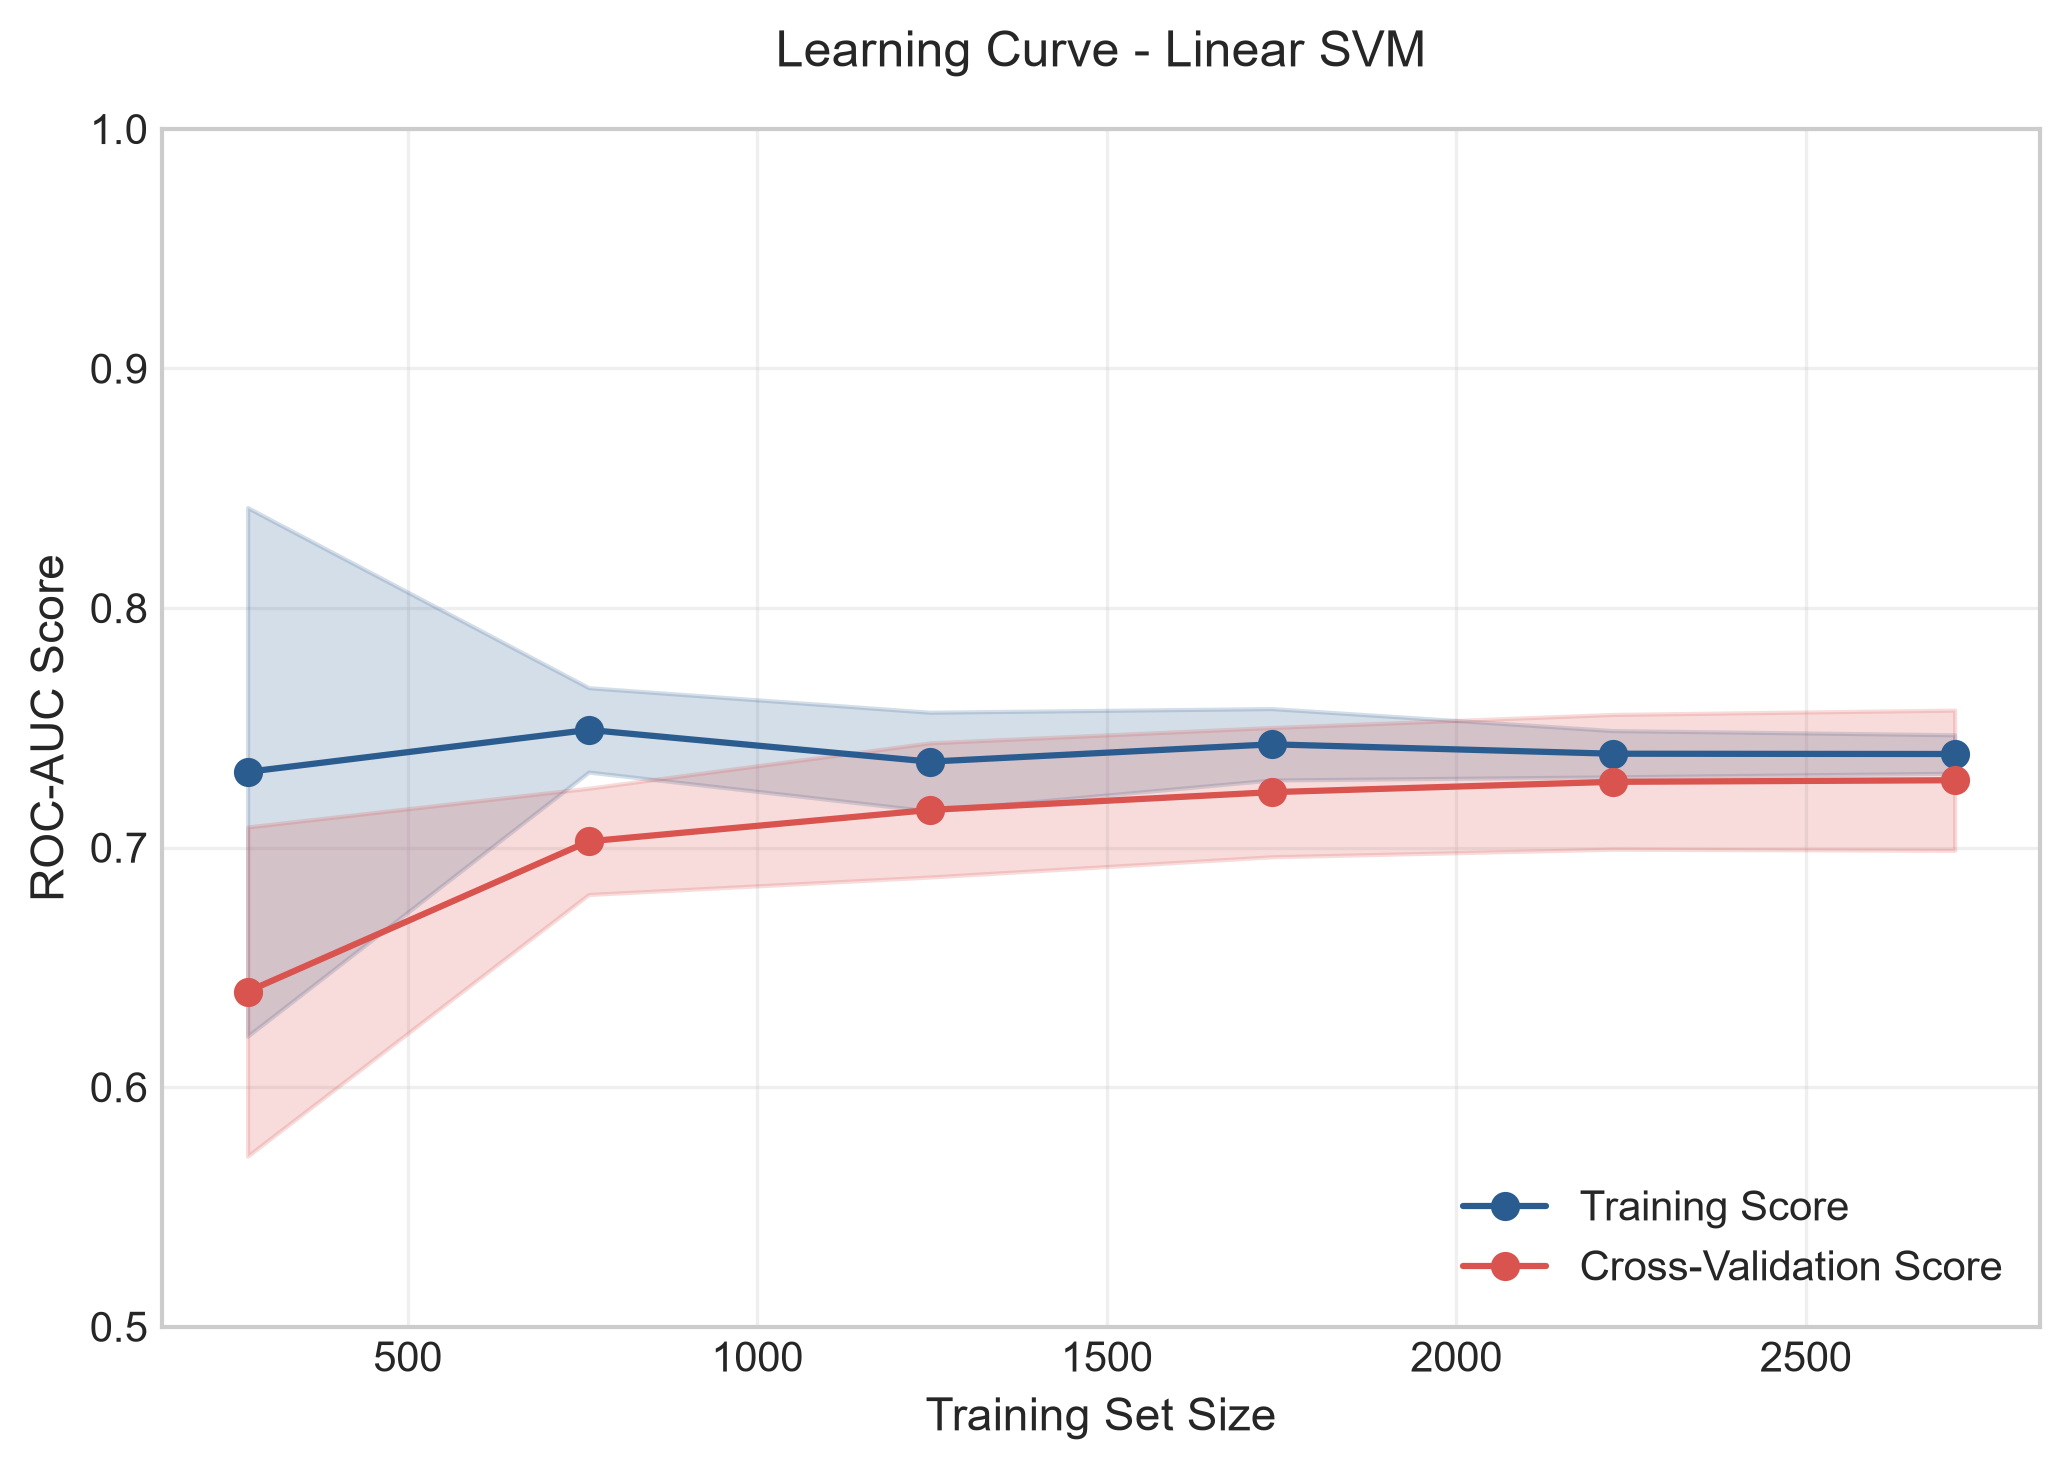

In [27]:
# 12.4. Learning Curve - Linear SVM (tai hinh da luu)
print('12.4. Learning Curve - Linear SVM (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/svm_linear_learning_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

12.5. Learning Curve - RBF SVM (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/svm_rbf_learning_curve.png


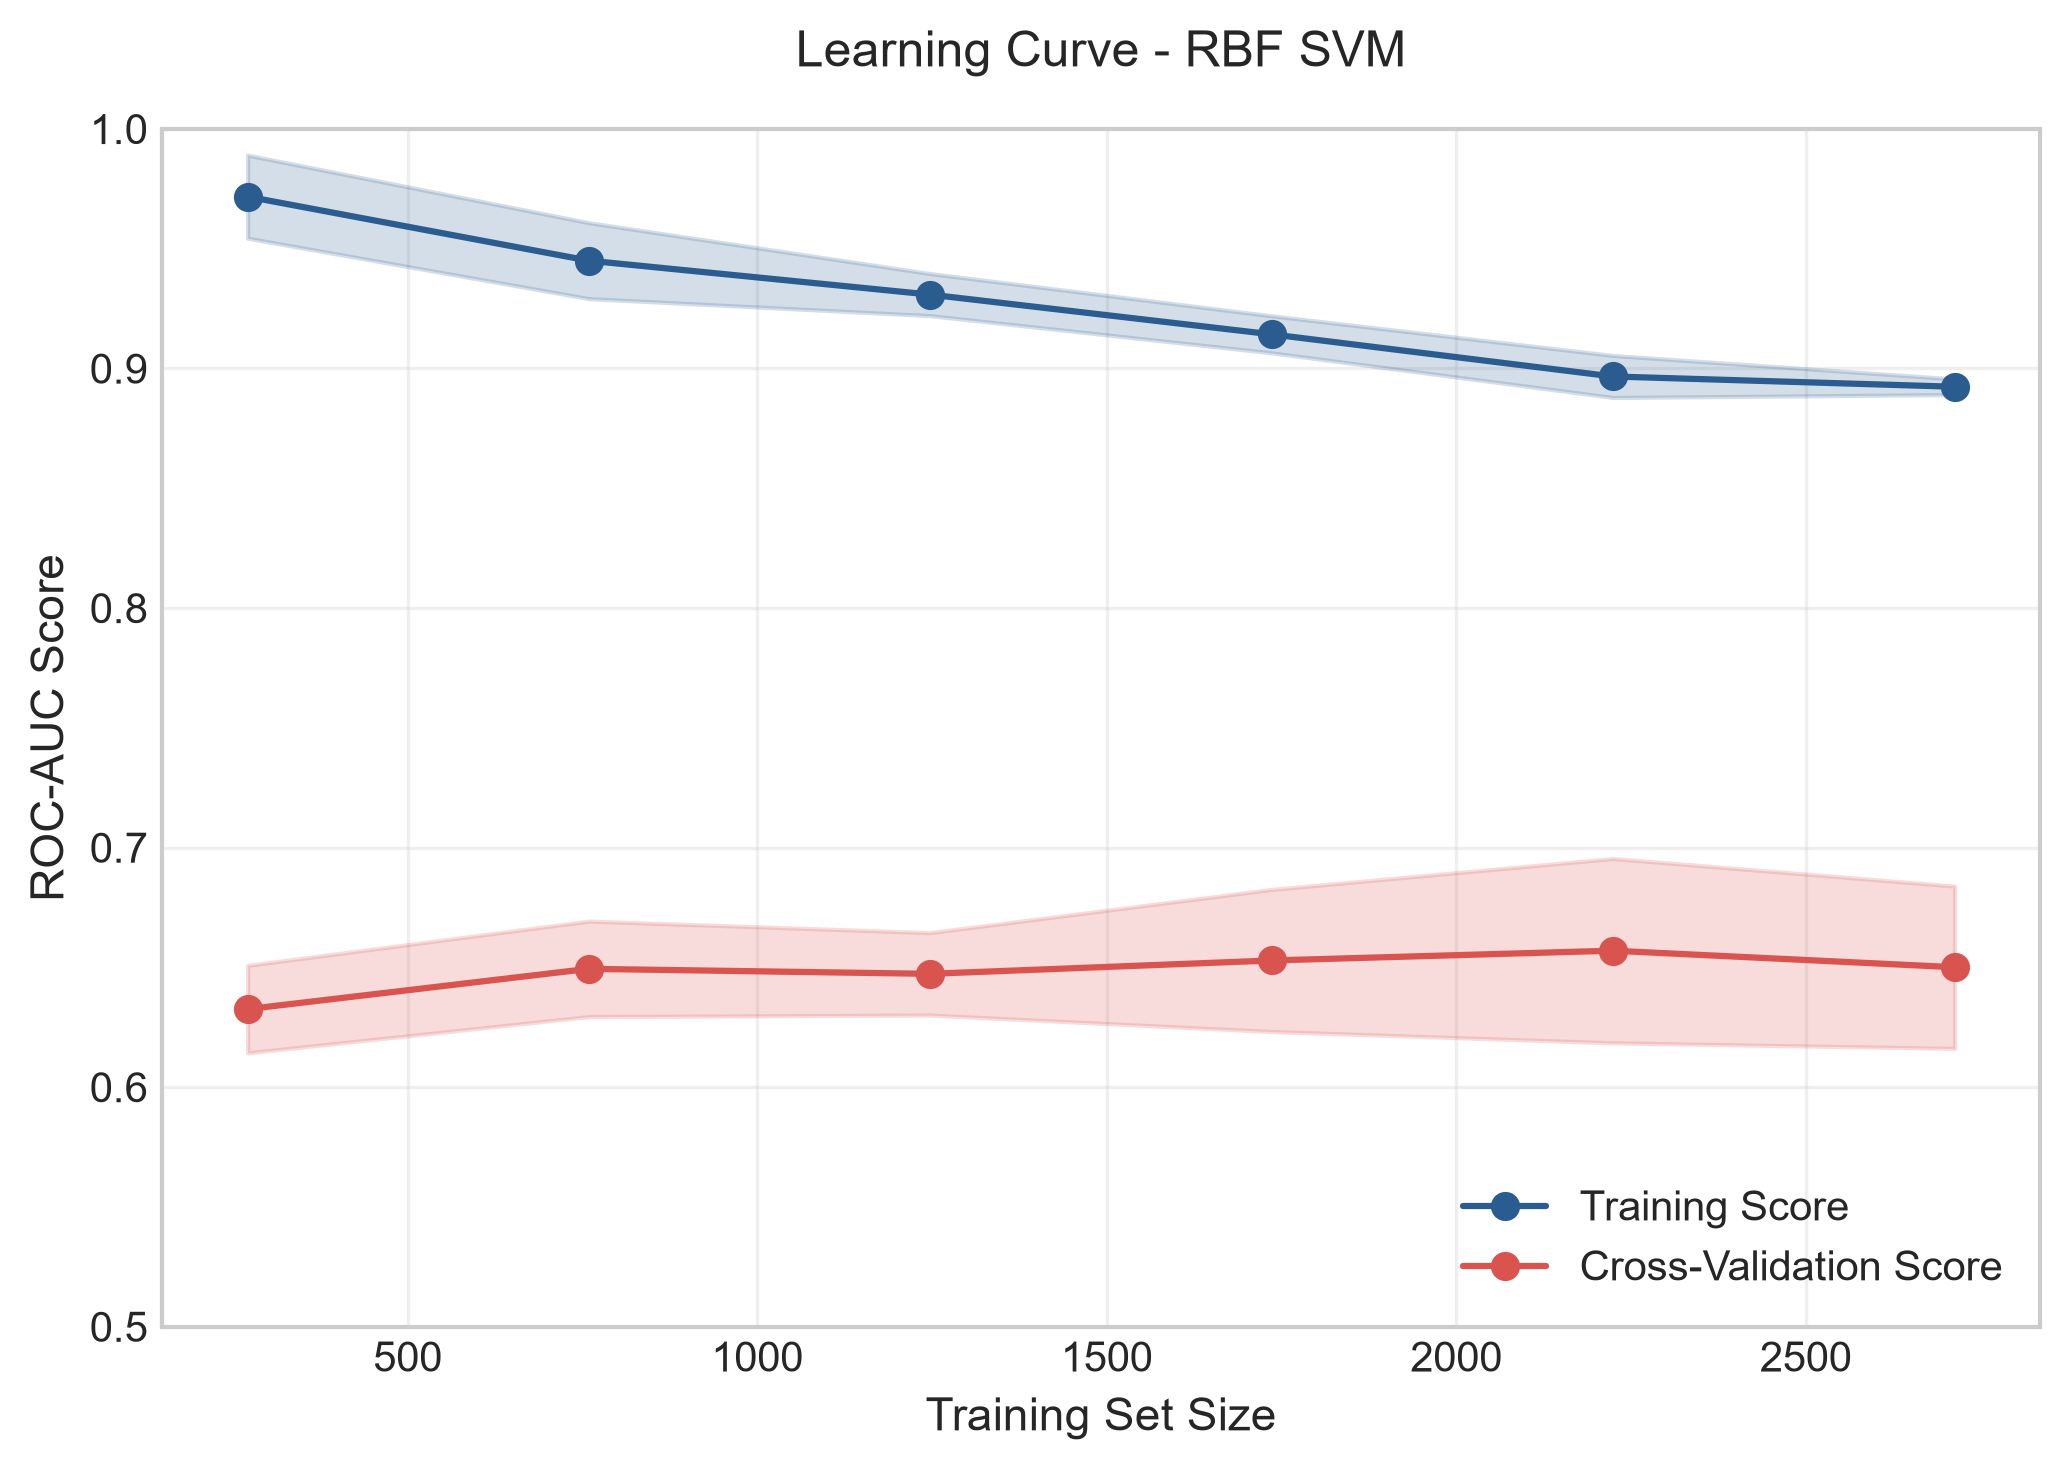

In [28]:
# 12.5. Learning Curve - RBF SVM (tai hinh da luu)
print('12.5. Learning Curve - RBF SVM (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/svm_rbf_learning_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

## 13. Validation Curves
Phan tich tac dong cua sieu tham so quan trong

In [29]:
# 13.1. Ham ve Validation Curve
def plot_validation_curve(estimator, title, X, y, param_name, param_range, cv,
                          scoring='roc_auc', figsize=(7, 5), save_path=None):
    train_scores, test_scores = validation_curve(
        estimator, X, y,
        param_name=param_name,
        param_range=param_range,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    ax.plot(param_range, train_mean, 'o-', color='#2b5c8f', label='Training Score')
    ax.fill_between(param_range, train_mean - train_std, train_mean + train_std,
                    alpha=0.2, color='#2b5c8f')
    ax.plot(param_range, test_mean, 'o-', color='#d9534f', label='Cross-Validation Score')
    ax.fill_between(param_range, test_mean - test_std, test_mean + test_std,
                    alpha=0.2, color='#d9534f')

    ax.set_xlabel(param_name.replace('classifier__', ''), fontsize=11)
    ax.set_ylabel('ROC-AUC Score', fontsize=11)
    ax.set_title(title, fontsize=12, pad=15)
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.5, 1.0)
    
    if all(isinstance(x, (int, float)) and x > 0 for x in param_range):
        if max(param_range) / min(param_range) > 10:
            ax.set_xscale('log')

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    return train_scores, test_scores

13.2. Validation Curve - k-NN (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/knn_validation_curve.png


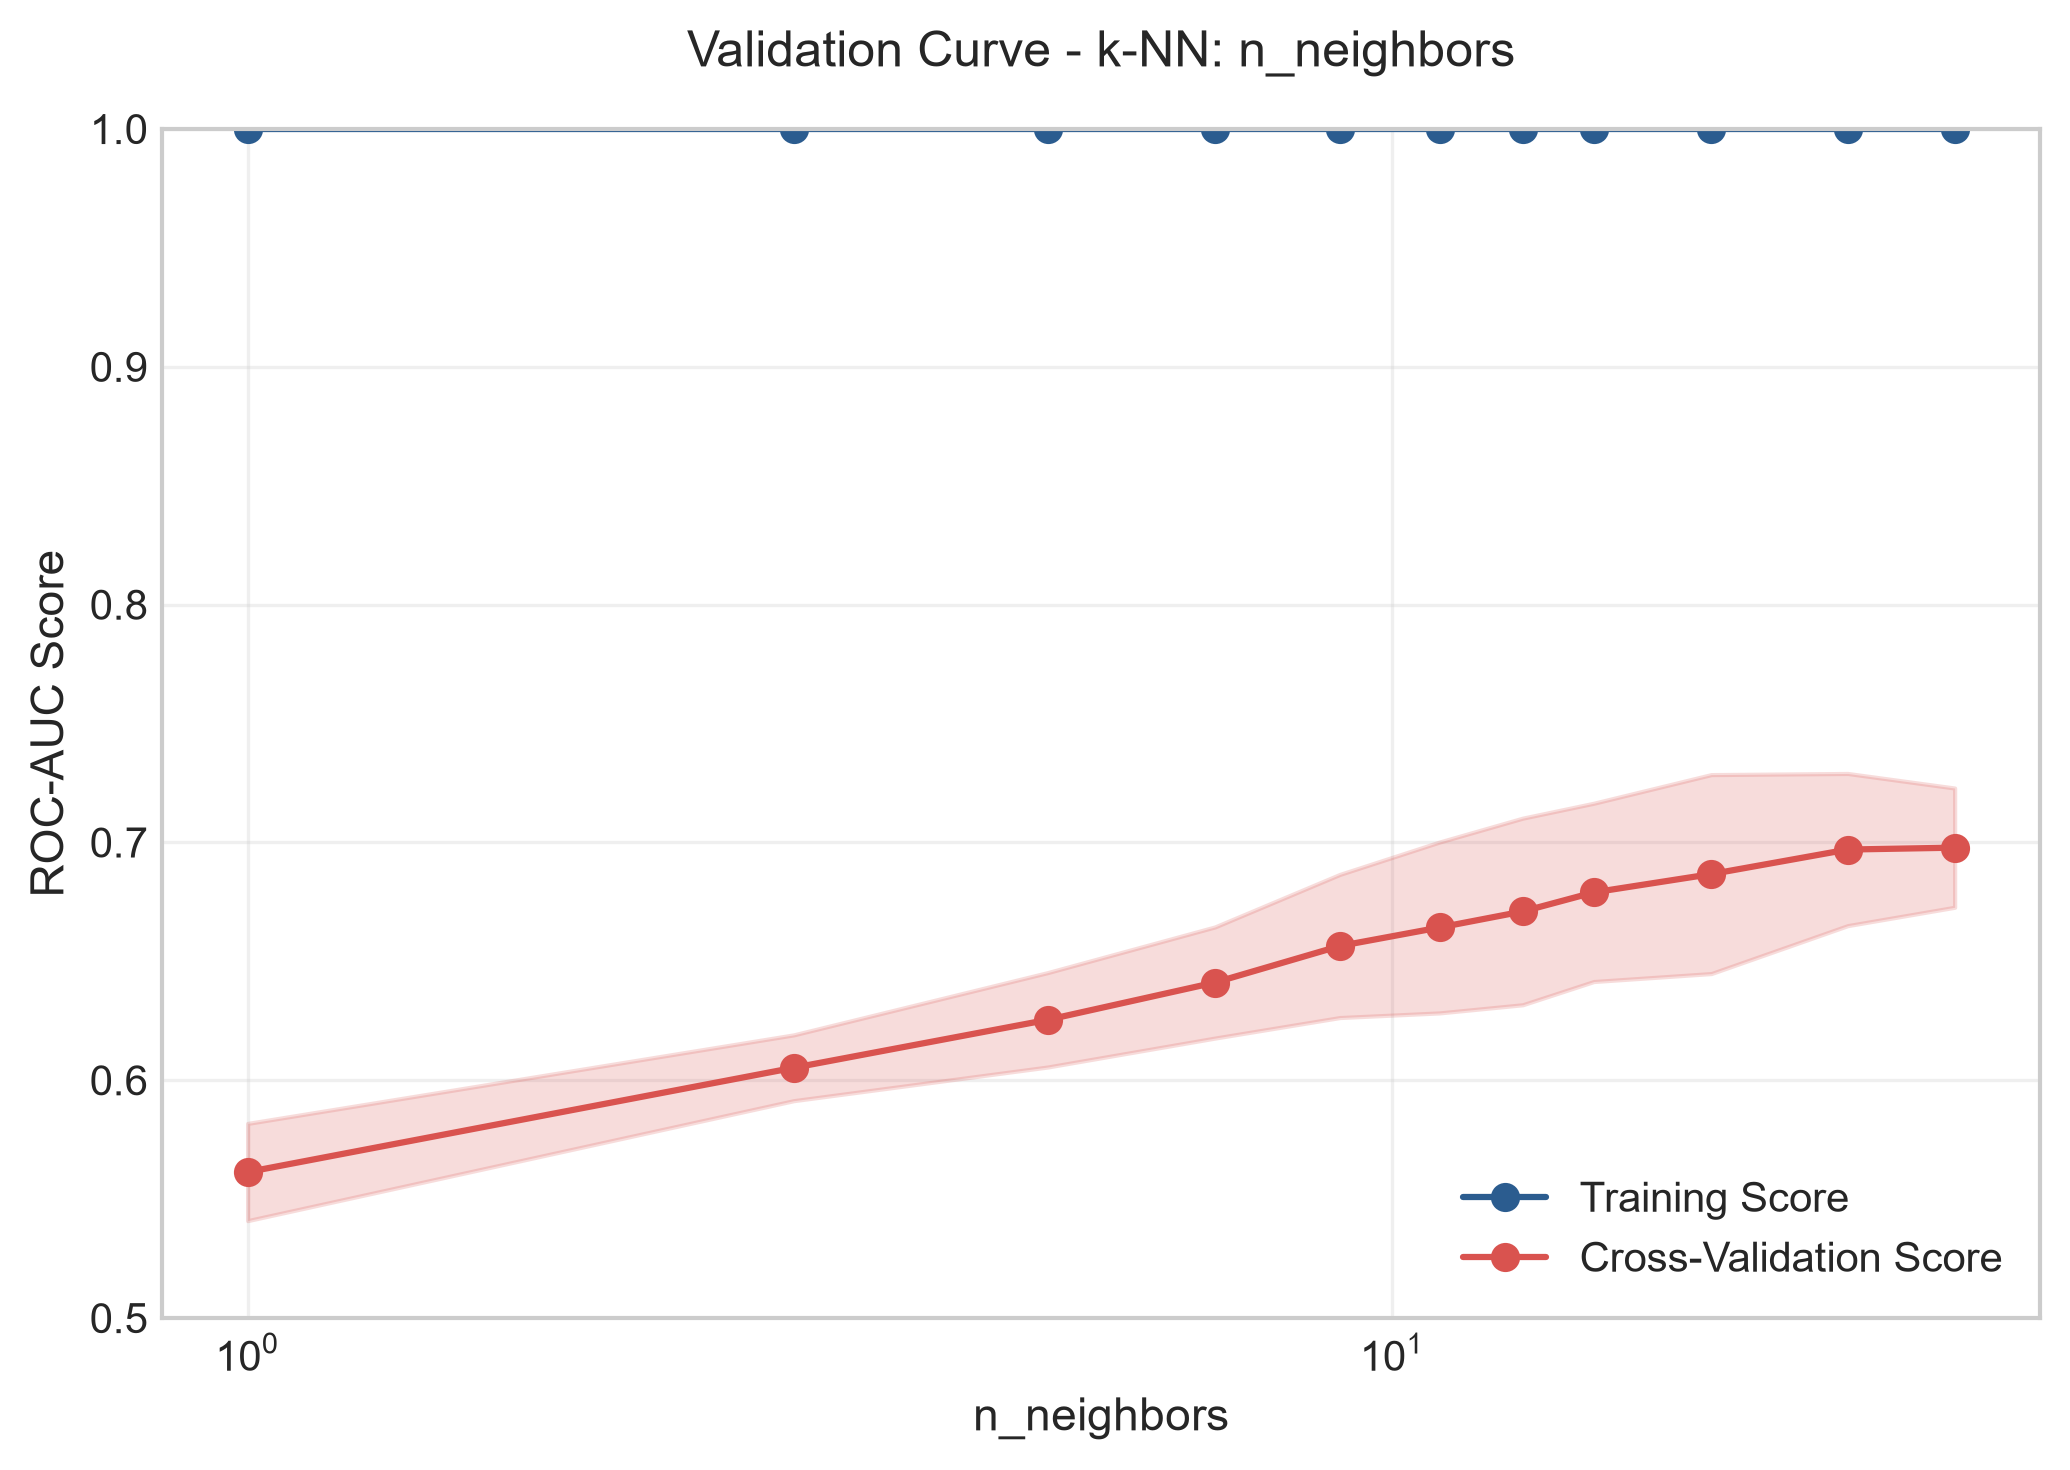

In [30]:
# 13.2. Validation Curve - k-NN (tai hinh da luu)
print('13.2. Validation Curve - k-NN (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/knn_validation_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

13.3. Validation Curve - Linear SVM (tai hinh da luu)
Da tai hinh anh: ../notebooks/figures/svm_linear_validation_curve.png


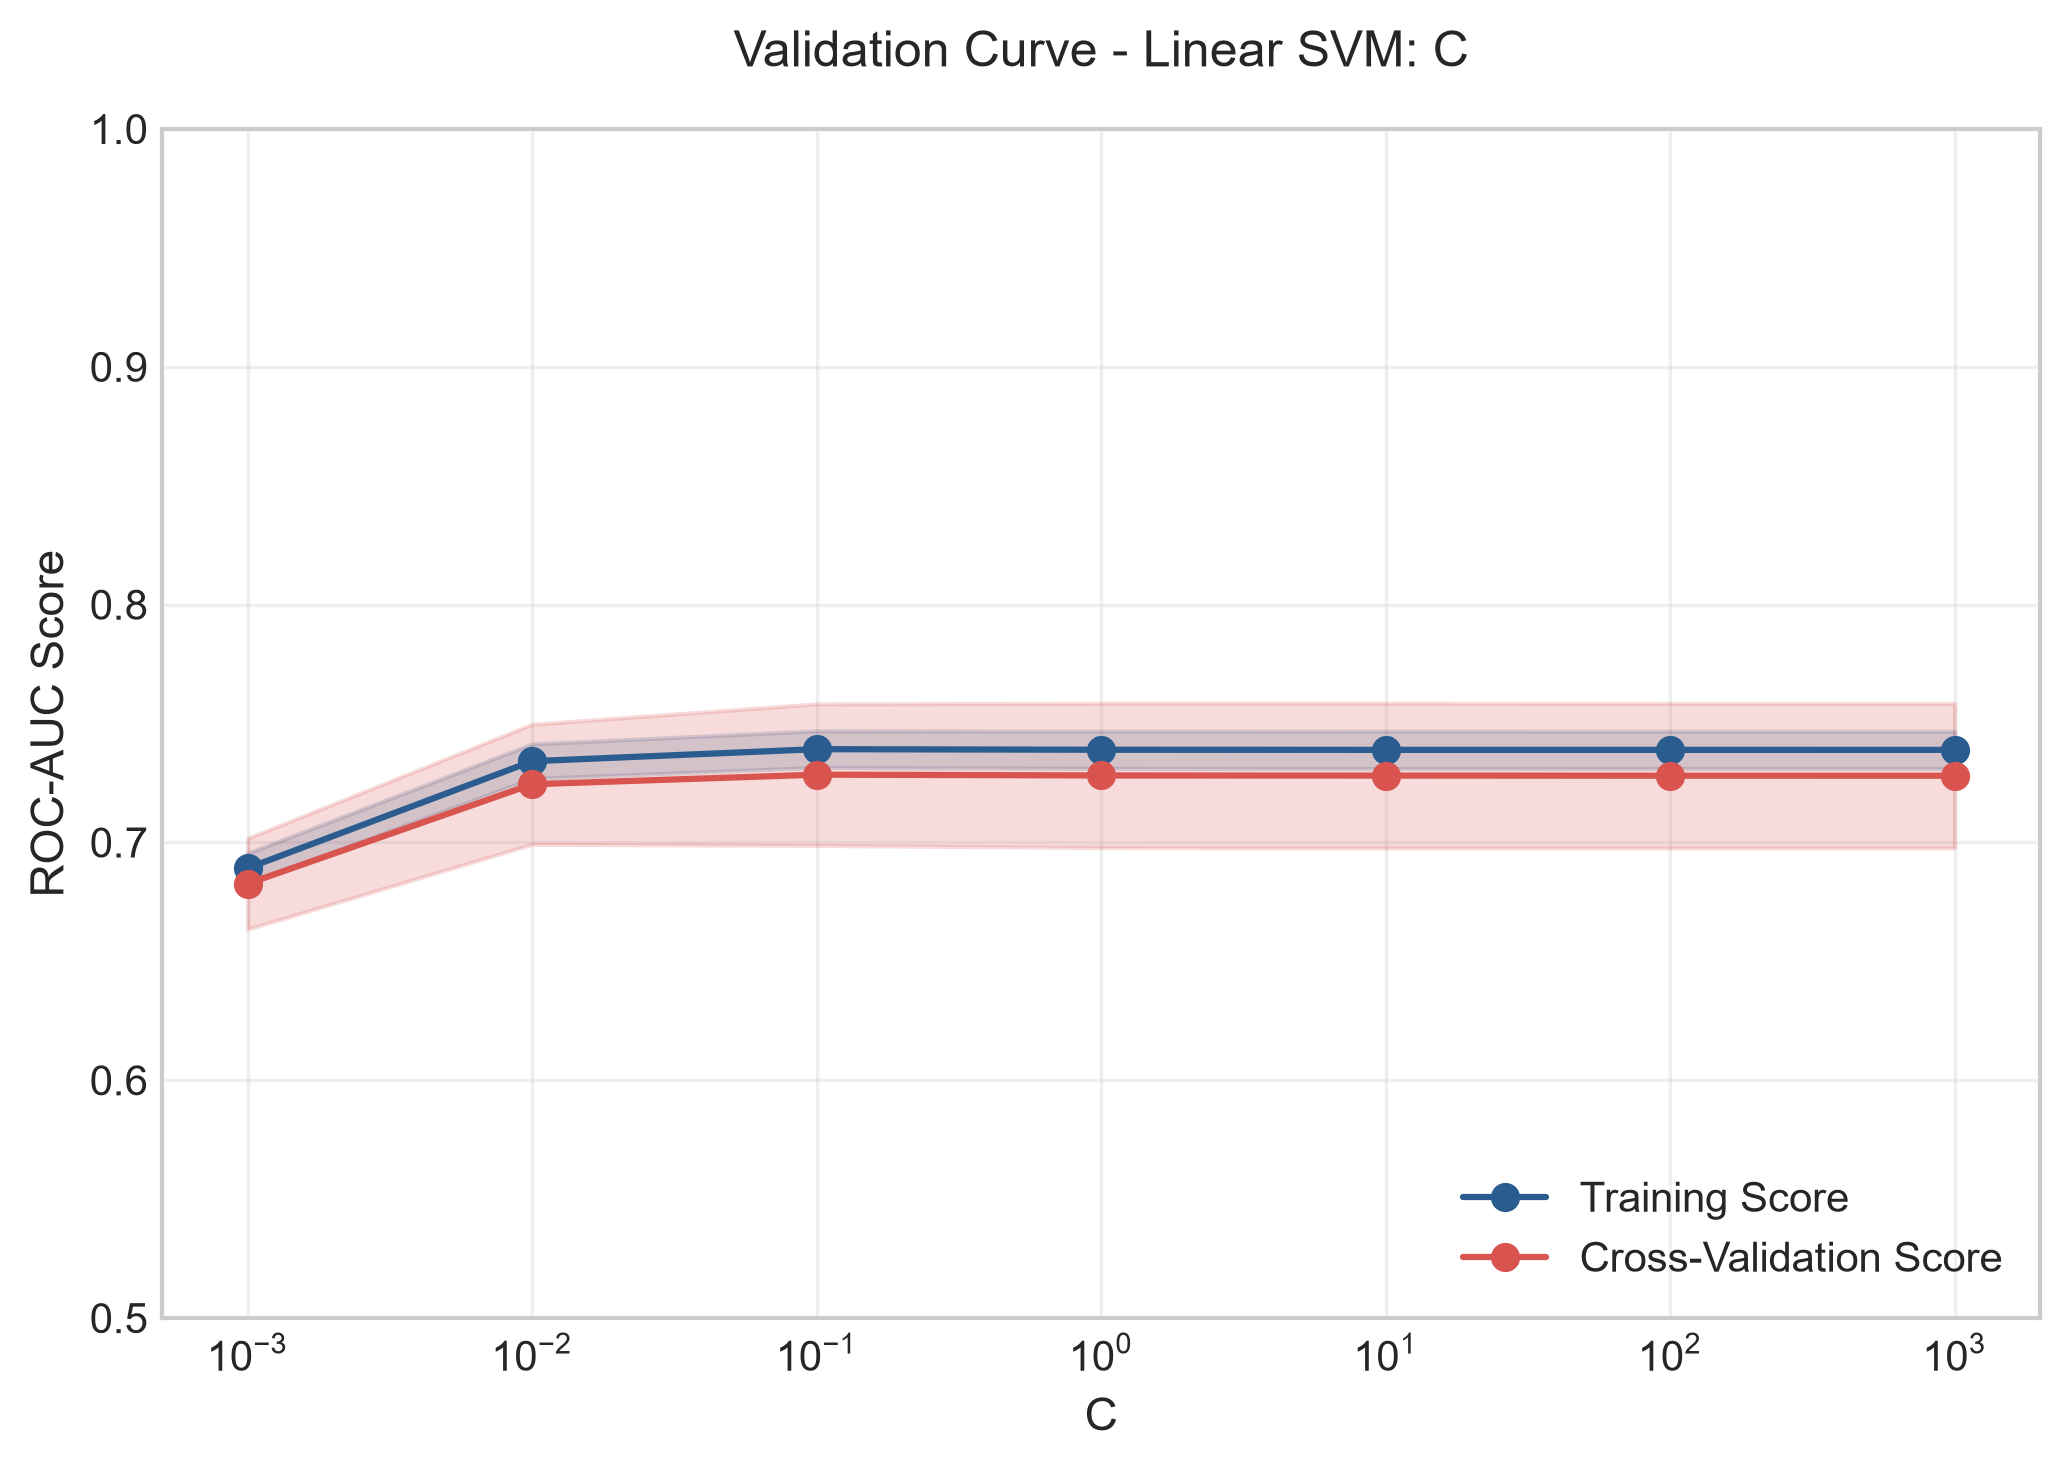

In [31]:
# 13.3. Validation Curve - Linear SVM (tai hinh da luu)
print('13.3. Validation Curve - Linear SVM (tai hinh da luu)')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/svm_linear_validation_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

Tai gamma tot nhat va hien thi Validation Curve RBF SVM da luu...
Best gamma: 0.01
Da tai hinh anh: ../notebooks/figures/svm_rbf_validation_curve.png


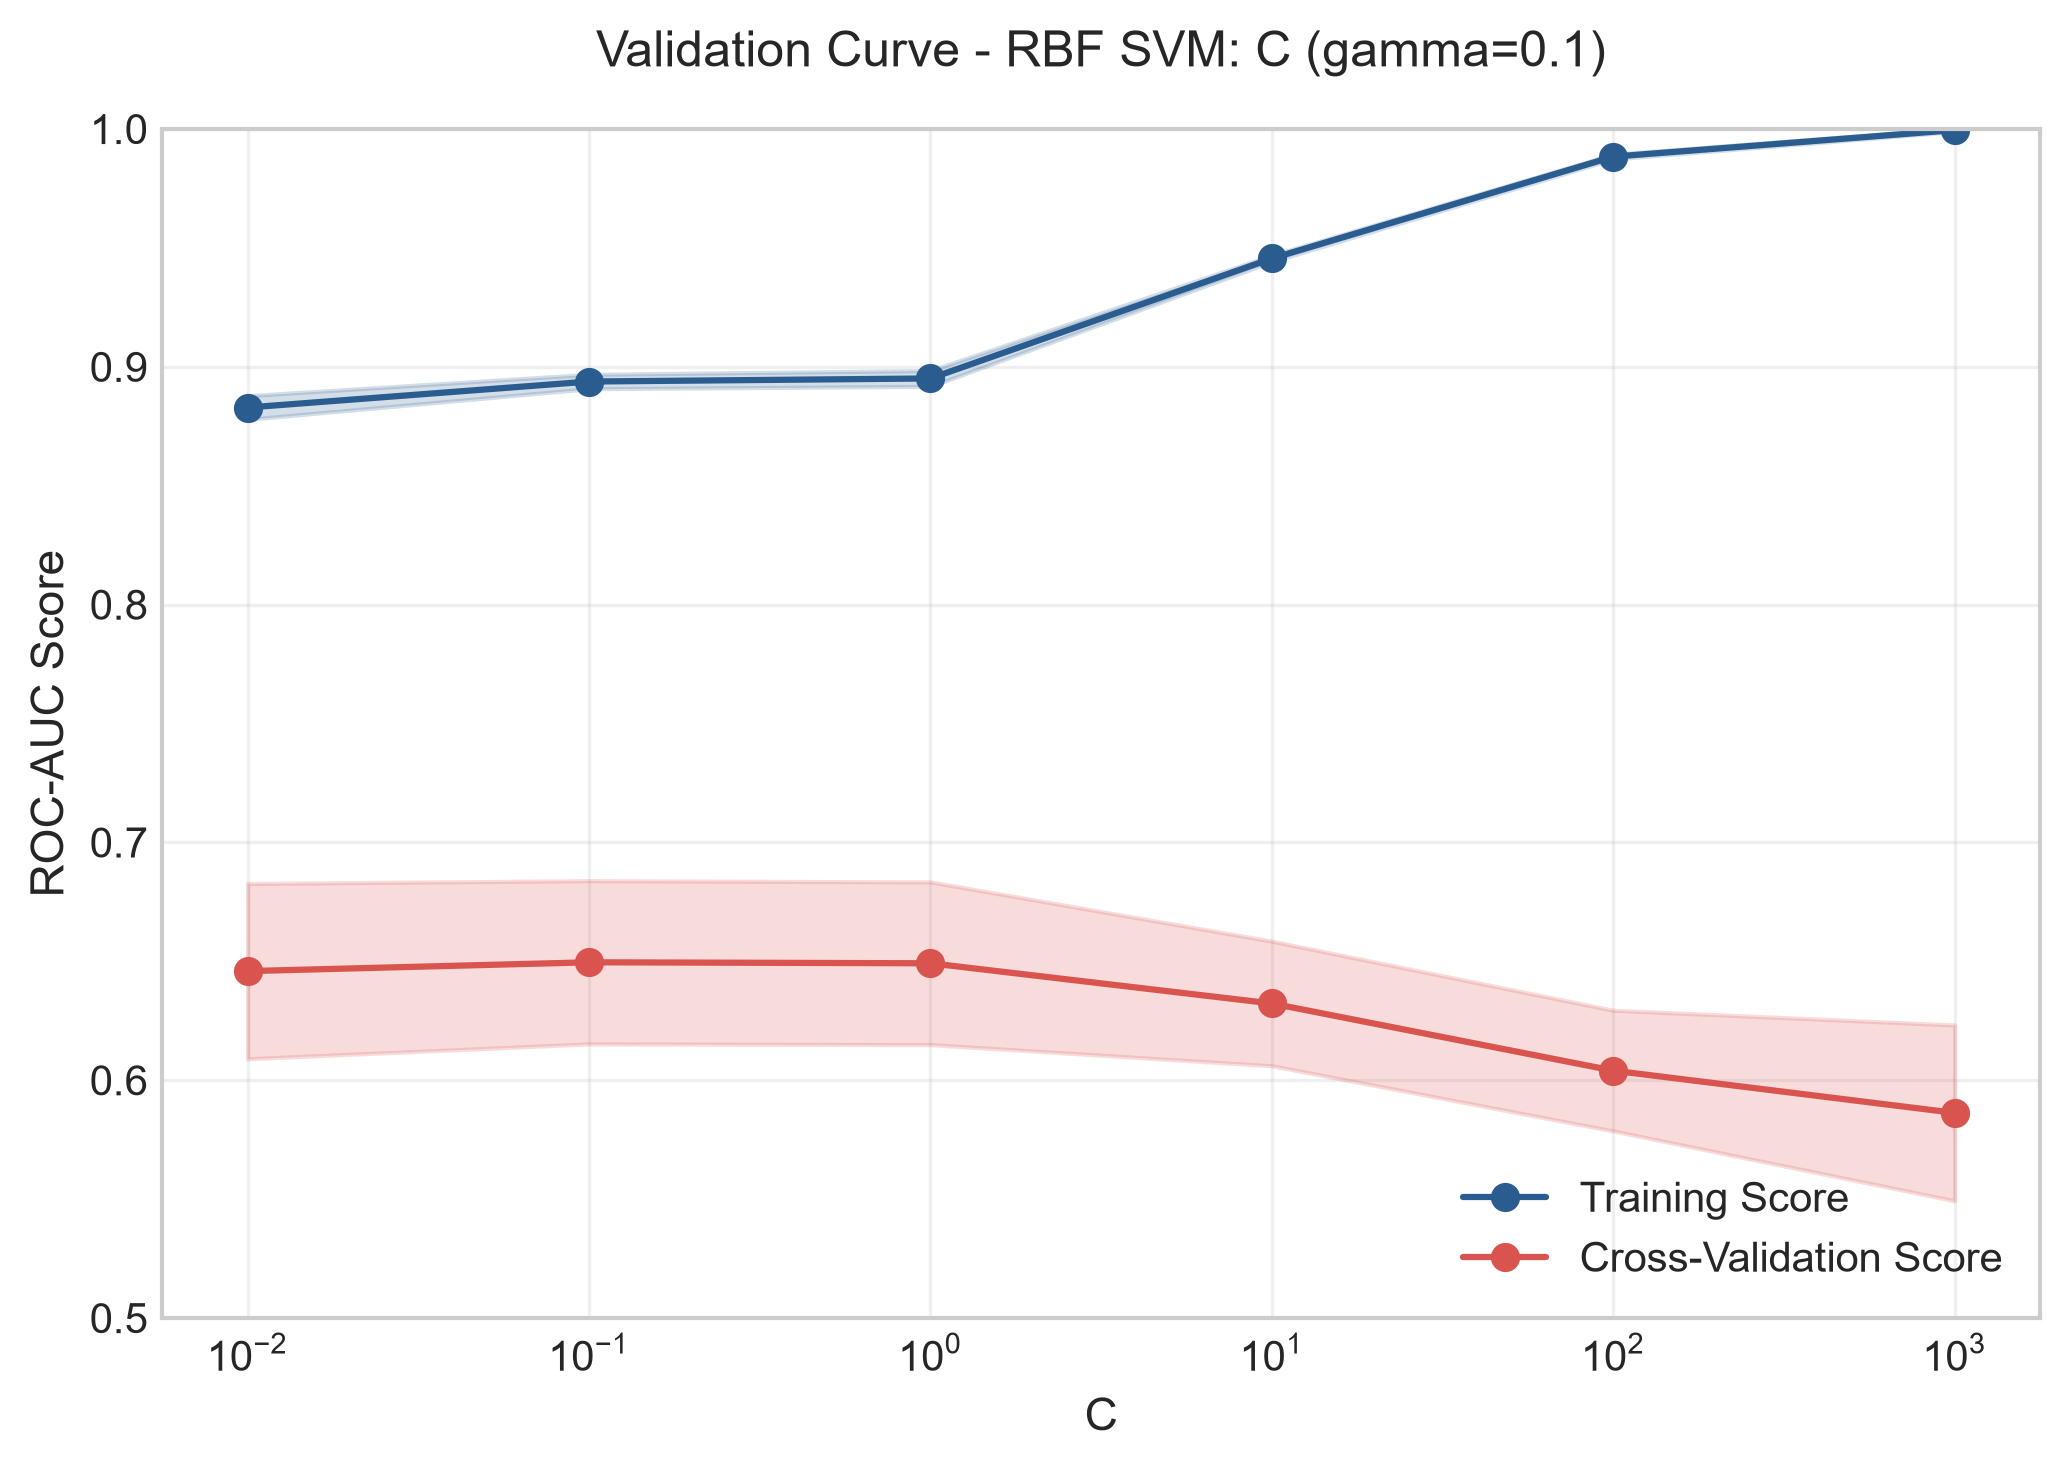

In [32]:
# 13.4. Validation Curve - RBF SVM (tai hinh da luu)
print('Tai gamma tot nhat va hien thi Validation Curve RBF SVM da luu...')
svm_rbf_best = pd.read_csv('../models/results/svm_rbf_best_params.csv').iloc[0].to_dict()
best_gamma = svm_rbf_best['classifier__gamma']
print(f'Best gamma: {best_gamma}')
from IPython.display import display, Image
import os as _os
fig_path = '../notebooks/figures/svm_rbf_validation_curve.png'
print(f'Da tai hinh anh: {fig_path}')
if _os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print('Khong tim thay hinh anh:', fig_path)

## 14. Thao luan: Overfitting, Underfitting va Hoi tu
### Phan tich Learning Curves:
- <b>Logistic Regression</b>: Duong training va CV hoi tu gan nhau -> mo hinh on dinh, it overfitting
- <b>k-NN</b>: Training score cao, CV score thap hon -> co dau hieu overfitting nhe khi k nho
- <b>Linear SVM</b>: Training va CV gan nhau -> regularization tot kiem soat overfitting
- <b>RBF SVM</b>: Can quan sat gap giua training va CV de danh gia overfitting

### Phan tich Validation Curves:
- <b>k-NN (n_neighbors)</b>: k nho -> overfitting (high variance); k lon -> underfitting (high bias)
- <b>Linear SVM (C)</b>: C nho -> underfitting; C lon -> co the overfitting
- <b>RBF SVM (C)</b>: Tuong tu, gamma duoc co dinh o gia tri tot nhat

### Ket luan thuc nghiem:
1. Logistic Regression baseline la mo hinh can bang tot
2. k-NN can chon k phu hop (distance weighting giup cai thien)
3. SVM (Linear/RBF) can tuning C can than
4. Mo hinh tot nhat duoc chon dua tren Test ROC-AUC

## 15. Ket luan Thuc nghiem
### Tom tat ket qua:
1. <b>Baseline Logistic Regression</b>: Don gian, nhanh, on dinh, ROC-AUC test ~0.70
2. <b>k-NN</b>: Cai thien duoc Recall nhở distance weighting, những chảm hơn
3. <b>Linear SVM</b>: Hiệu quả tương duong LR, có thể tốt hơn o margin lon
4. <b>RBF SVM</b>: Linh hoat nhất những tồn tính toán, cần tuning gamma

### Khuyen nghi cho Milestone 3:
- Ensemble methods (Random Forest, Gradient Boosting, XGBoost)
- Threshold optimization cho Recall cao (y te)
- Calibration xac suat
- Feature selection nang cao